[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionAudit_Gillani2026.ipynb)

# Hybrid VQC and quantum-kernel SVM for network intrusion detection: "How Quantum Is the Advantage?" step by step

**Paper.** Syeda Anshrah Gillani, Mirza Samad Ahmed Baig, Shahid Munir Shah, Asher Ali, Hamzah Siddiqui,
*How Quantum Is the Advantage? A Fair, Calibration- and Noise-Aware Benchmark and Attribution Audit of Quantum Machine
Learning for Network Intrusion Detection*, arXiv:2608.18155 [quant-ph], 13 Aug 2026, <https://arxiv.org/abs/2608.18155>.
Authors' code: <https://github.com/Orqly-AI/quantum-ids-benchmark> (this notebook pins commit `1c8acf2`).

**What this notebook does.** The paper does not propose a new quantum model. It asks a sceptical question: when a quantum
intrusion detector reaches "99 % accuracy", *how much of that is genuinely quantum*? It (i) benchmarks hybrid variational
quantum circuits (VQC) and quantum-kernel SVMs (QSVM) against honestly tuned classical models on four IDS datasets under a
leakage-controlled protocol, (ii) runs a **quantum-attribution audit** (parameter-matched classical controls, a random-feature
kernel as the classical surrogate of the quantum kernel, a regularisation sweep, Benjamini-Hochberg FDR control), and (iii) sweeps
simulated NISQ noise. This notebook re-runs those experiments on a CPU simulator, **re-using the authors' released model code**,
checks every number it can against the paper, and ends with an honest verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default) is a class demo that finishes in
roughly 10 minutes locally; `FAST_MODE = False` uses the larger budgets listed in the configuration cell. Data are downloaded
inside the notebook (public mirrors, cached in `DATA_DIR`, large raw files deleted after sampling).

**What you get at the end.** Class-distribution and PCA scatter plots of the real data, the executed quantum circuits drawn with
`qml.draw_mpl`, the full benchmark and attribution tables, a noise sweep, and a paper-versus-notebook table with a verdict for each claim.

> **Attribution and licence notice (please read).** *Original Work by: Mirza Samad Ahmed Baig and Syeda Anshrah Gillani
> (Orqly-AI), Copyright (c) 2026. Source: <https://github.com/Orqly-AI/quantum-ids-benchmark>.* The authors' code is released
> under their *Orqly-AI Restricted Attribution License (ORAL) v1.0*: personal, academic and **non-commercial use only**,
> mandatory attribution, no reproduction of the paper itself. This notebook therefore does **not copy** their code or paper text:
> at run time it downloads four of their source files (`quantum_model.py`, `attribution.py`, `evaluation.py`, `baselines.py`)
> from the pinned commit and imports them; the notebook's own code is orchestration around them. Paper numbers appear only as short
> reference values for the comparison table. Do not use this notebook commercially; cite the paper (above) if you use its results.

## The paper in one page

**Problem.** Quantum ML for network intrusion detection (NIDS) routinely reports 97-99.9 % accuracy, but (a) the quantum model usually
sees a heavily PCA-reduced input (one feature per qubit), (b) evaluation is often random cross-validation, which hides how badly models
generalise to *new* attacks, (c) classical baselines are under-tuned, and (d) Bellante et al. argued that PCA-based quantum IDS gains can
be explained by classical regularisation. The paper asks *how quantum* a measured advantage really is.

**Decision.** Per connection or flow record: benign (0) vs attack (1) (binary task; the multiclass labels are only used for plots).
Because false alarms flood analysts, the detector is also judged at a *low false-positive-rate operating point* (TPR at 0.1 % and 1 % FPR).

**Method (Sec. 4).**
- *Protocol.* Official splits are honoured: NSL-KDD `KDDTrain+` / `KDDTest+` (17 attack signatures occur only in the test set), UNSW-NB15 official CSVs;
  CICIDS2017 and NF-ToN-IoT-v2 use a seeded stratified 70/30 split. All preprocessing is fitted on the training split only.
- *Two feature views.* **full** (classical models on every one-hot dimension, the practical ceiling) and **same-budget** (every model on the same 8 PCA components
  the 8-qubit models receive; min-max scaling *before* PCA keeps 84 % of the variance on NSL-KDD instead of 27 %).
- *Quantum models.* Hybrid VQC = classical `Linear -> Tanh` pre-layer, a variational circuit (angle / IQP-ZZ / amplitude / data-re-uploading encoding;
  `StronglyEntanglingLayers` or `BasicEntanglerLayers` ansatz; read-out of `<Z_i>` on every qubit), and a classical `Linear` read-out; plus two QSVMs
  (IQP fidelity kernel, angle projected kernel).
- *Classical baselines.* RF, XGBoost, RBF-SVM, tuned MLP, 1D-CNN, each hyper-parameter-searched with stratified CV on the training split and refit per seed.
- *Attribution audit.* Parameter-matched MLP for every hybrid, a random-feature kernel (RBFSampler / Nystroem) for every QSVM, a regularisation sweep,
  paired tests (McNemar, paired t / Wilcoxon, paired bootstrap) and Benjamini-Hochberg FDR correction.
- *Noise.* Depolarising, amplitude-damping, phase-damping and bit-flip channels at p in {0, 0.001, 0.005, 0.01, 0.05} on PennyLane `default.mixed`.

**Data (Table 2).** NSL-KDD (125,973 / 22,544 flows, 122 one-hot dims), UNSW-NB15 (175,341 / 82,332, 194 dims), CICIDS2017 (3-day subset, ~1.04 M flows, 76 dims),
NF-ToN-IoT-v2 (200,000-row stratified down-sample of 16.9 M, 39 dims).

**Headline claims to check.** (1) Tuned classical models match or beat the quantum models on aggregate F1 on every dataset (e.g. NSL-KDD same-budget F1 0.782 vs 0.730).
(2) The CV-to-test gap on NSL-KDD is about 0.20 F1. (3) Once a classical model gets the same front-end and regularisation, the aggregate quantum advantage disappears.
(4) Two FDR-robust exceptions: the IQP quantum-kernel SVM beats its random-feature surrogate (AUPRC +0.075, ROC-AUC +0.134, TPR@1 %FPR +0.152), and a **4-qubit** hybrid beats the best classical
model at TPR@1 %FPR on NSL-KDD (0.517 vs 0.467, p = 0.005). (5) The advantage vanishes at 12 qubits. (6) Mild simulated noise does not hurt; only readout (bit-flip) noise does.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | NSL-KDD, UNSW-NB15, CICIDS2017 (3-day), NF-ToN-IoT-v2 (200 k rows) | Same four. NSL-KDD: full official split (125,973 / 22,544). UNSW-NB15: official files, **stratified sub-sample** (rows in the configuration cell). CICIDS2017: Tuesday + Friday-DDoS + Friday-PortScan files, stratified sub-sample, 70/30 split (`# CHOICE:` the paper's exact 3 days are not stated). NF-ToN-IoT-v2: `test.csv` of the Hugging Face mirror, stratified sub-sample |
| Feature views | full and same-budget (min-max -> PCA 8) | Identical: min-max[0,1] -> PCA(8) -> min-max[0, pi]; test angles clipped to [0, pi] (`# CHOICE:`); all fitted on the training split only |
| Hybrid VQC | angle/IQP/amplitude/re-upload x SE/BE, 8 qubits main, 4-12 qubits ablation | The authors' own `HybridQNN` class (pinned commit). 8 qubits x 3 layers; angle-SE and IQP-SE always, angle-BE and re-upload-SE in the full run; amplitude encoding not run (`# CHOICE:` unstable per the paper itself). Qubit ablation 4 / 8 / 12 |
| Simulator | PennyLane `lightning.qubit` + adjoint (CPU), per-sample loop | PennyLane `default.qubit` with parameter broadcasting + torch back-prop (`# CHOICE:` ~10x faster here; the equivalence check below proves identical outputs) |
| Training budget | not stated in the paper; authors' sweep: 2,000 rows, 20 epochs, batch 64, Adam lr 0.005, balanced class weights, 3 seeds | FAST: 600 rows x 6 epochs x 2 seeds. Full: the authors' 2,000 rows x 20 epochs x 3 seeds (12-qubit model smaller, see config) |
| QSVM | IQP fidelity kernel, angle projected kernel; train subsample | Same two kernels computed *exactly* from batched statevectors (equals the authors' circuit-by-circuit kernel, asserted); 500 (FAST) / 1,500 (full) training rows |
| Classical baselines | RF, XGBoost, RBF-SVM, tuned MLP, 1D-CNN; randomized search, 5-fold CV, 5 seeds on NSL-KDD | Authors' `tune_sklearn_baseline` with a **much smaller** search (candidates / folds in the config), tree ensembles capped at `MAX_TREES`, SVM on a row cap, MLP/CNN with the authors' released best hyper-parameters and a short epoch budget (`# CHOICE:`) |
| Attribution audit | matched MLP, rf-kernel, regularisation sweep, paired tests, BH-FDR over 108 comparisons | Same controls and the authors' `matched_mlp_for_qnn`, `RandomFeatureKernelSVM`, `paired_bootstrap`, `mcnemar_test`; BH over **our** (smaller) comparison family; bootstrap resamples fewer than 2,000 |
| Noise sweep | models *trained* under noise, 6 qubits, 4 channels x 5 strengths, 2 seeds | Noiseless training with the authors' layer-by-layer circuit, noise applied at *inference* on `default.mixed`, 4 channels x p in {0.01, 0.05}, subset of the test set (`# CHOICE:` cost) |
| Backend timing (CPU vs GPU) | RTX 3050 Ti | **cannot be checked** (no GPU); we time the authors' `lightning.qubit` against the broadcast `default.qubit` instead |
| Hardware | none (simulation only) | none |

## 0. Setup

The next cells pin the installs, define the single configuration cell, import everything and download the authors' source files from the pinned commit.
`FAST_MODE` controls every budget. Quantum training is *per-sample expensive* on a simulator, so (exactly like the authors) the hybrid VQCs are trained on a few
hundred to two thousand stratified training rows while the **test sets are the full official ones** (NSL-KDD: all 22,544 flows).

In [1]:
# Pinned installs (tested versions). Colab already ships numpy/pandas/scikit-learn/matplotlib/torch; a runtime
# restart may be requested after the install - if so, restart and "Run all" again.
import importlib, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not (_have("pennylane") and _have("torch") and _have("xgboost")):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pennylane-lightning==0.45.0",
                    "xgboost", "huggingface_hub", "pyarrow", "requests"], check=False)
    if not _have("torch"):          # CPU torch only if the runtime does not already ship it
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch", "--index-url",
                        "https://download.pytorch.org/whl/cpu"], check=False)


In [2]:
# ---------------------------------------------------------------- configuration (every tunable constant)
SEED = 42
FAST_MODE = True            # True: ~10-minute class demo (small budgets). False: the paper-sized budgets below.
IBM_TOKEN = ""              # unused: the paper is simulation-only (no QPU access); kept for the factory convention
DATA_DIR = "qids_data"      # cache for datasets and the authors' source files
AUTHORS_COMMIT = "1c8acf207b1e4d56a613287fd57e79af399ce234"   # Orqly-AI/quantum-ids-benchmark, pinned

N_QUBITS = 8                # main configuration of the paper (n_features = n_qubits = 8)
N_LAYERS = 3                # ansatz depth of the main hybrid VQC (authors' sweep_main.yaml)
BATCH, LR = 64, 0.005       # authors' runner defaults for the hybrid VQC
CLASS_WEIGHT = True         # cost-sensitive learning (paper Sec. 4.5): balanced class weights

if FAST_MODE:
    Q_SEEDS, C_SEEDS = (42, 43), (42, 43)
    Q_TRAIN, Q_EPOCHS = 600, 6                  # training rows / epochs of every hybrid VQC
    QSVM_N, RFK_N = 500, 500                    # kernel-method training rows
    TUNE_ITER, TUNE_CV, TUNE_ROWS = 3, 3, 6000  # randomized search: candidates / folds / search rows
    C_TRAIN_CAP, SVM_CAP = 25000, 4000          # rows used to refit RF/XGB, SVM (NSL-KDD)
    NN_EPOCHS, NN_BATCH, NN_CAP, MAX_TREES = 3, 256, 20000, 100   # tuned MLP / 1D-CNN baselines; training-row cap; tree cap
    ABL_QUBITS, ABL_TEST_N, Q12_TRAIN, Q12_EPOCHS = (4, 8, 12), 3000, 600, 6
    NOISE_P, NOISE_TEST_N, NOISE_SEEDS = (0.01, 0.05), 1500, (42,)
    N_BOOT = 300                                # paired-bootstrap resamples (paper: 2000)
    X_TRAIN_CAP, X_TEST_CAP, X_Q_TRAIN, X_EPOCHS, X_SEEDS = 6000, 3000, 500, 5, (42,)   # other 3 datasets
else:
    Q_SEEDS, C_SEEDS = (42, 43, 44), (42, 43, 44, 45, 46)
    Q_TRAIN, Q_EPOCHS = 2000, 20                # authors' q_subsample / epochs
    QSVM_N, RFK_N = 1500, 1200
    TUNE_ITER, TUNE_CV, TUNE_ROWS = 10, 3, 20000
    C_TRAIN_CAP, SVM_CAP = 60000, 10000
    NN_EPOCHS, NN_BATCH, NN_CAP, MAX_TREES = 8, 256, 60000, 300
    ABL_QUBITS, ABL_TEST_N, Q12_TRAIN, Q12_EPOCHS = (4, 8, 12), 6000, 800, 8
    NOISE_P, NOISE_TEST_N, NOISE_SEEDS = (0.01, 0.05), 3000, (42, 43)
    N_BOOT = 1000
    X_TRAIN_CAP, X_TEST_CAP, X_Q_TRAIN, X_EPOCHS, X_SEEDS = 20000, 8000, 1000, 10, (42, 43)

NOISE_CHANNELS = ("depolarizing", "amplitude_damp", "phase_damp", "bit_flip")
print(f"FAST_MODE={FAST_MODE} | quantum seeds {Q_SEEDS} | classical seeds {C_SEEDS} | hybrid VQC: {Q_TRAIN} rows x {Q_EPOCHS} epochs")


FAST_MODE=True | quantum seeds (42, 43) | classical seeds (42, 43) | hybrid VQC: 600 rows x 6 epochs


In [3]:
import os, sys, warnings, random, urllib.request
warnings.filterwarnings("ignore")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("QIDS_N_JOBS", "2")          # n_jobs used by the authors' sklearn helpers
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import torch, sklearn, sklearn.ensemble, scipy, pennylane as qml
from scipy import stats

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
torch.set_num_threads(2)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token (only needed for gated datasets; the mirrors used here are public). In Colab add HF_TOKEN
# under Settings > Secrets if a mirror ever becomes gated; never paste a token into the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# ---- the authors' released harness (Orqly-AI/quantum-ids-benchmark, pinned commit). The source files are
# downloaded at run time and imported - they are NOT copied into this notebook (their licence, ORAL v1.0,
# is non-commercial and requires attribution; see the header of this notebook).
SRC_DIR = os.path.join(DATA_DIR, "authors_src")
os.makedirs(SRC_DIR, exist_ok=True)
for f in ("quantum_model.py", "attribution.py", "evaluation.py", "baselines.py"):
    dest = os.path.join(SRC_DIR, f)
    if not os.path.exists(dest):
        url = f"https://raw.githubusercontent.com/Orqly-AI/quantum-ids-benchmark/{AUTHORS_COMMIT}/src/{f}"
        urllib.request.urlretrieve(url, dest)
sys.path.insert(0, os.path.abspath(SRC_DIR))

print("Original Work by: Mirza Samad Ahmed Baig and Syeda Anshrah Gillani (Orqly-AI), Copyright (c) 2026")
print("Source: https://github.com/Orqly-AI/quantum-ids-benchmark @", AUTHORS_COMMIT[:10])
import xgboost
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__, "| xgboost", xgboost.__version__)


Original Work by: Mirza Samad Ahmed Baig and Syeda Anshrah Gillani (Orqly-AI), Copyright (c) 2026
Source: https://github.com/Orqly-AI/quantum-ids-benchmark @ 1c8acf207b
python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1


## 1. Data: four public IDS datasets

Every loader follows the paper's leakage control: identifier columns (IP addresses, ports, flow ids, timestamps) are dropped, text/categorical fields are one-hot encoded with
train/test columns aligned (test-only categories dropped), infinities and missing values are replaced by 0, and nothing is fitted on the test set.

| Dataset | Source used here | Split |
|---|---|---|
| NSL-KDD | GitHub `defcom17/NSL_KDD` (`KDDTrain+.txt`, `KDDTest+.txt`) | official |
| UNSW-NB15 | Hugging Face `research-simulation26/unsw-nb15-parquet` (official training/testing sets) | official, stratified sub-sample |
| CICIDS2017 | Hugging Face `c01dsnap/CIC-IDS2017` (MachineLearningCVE CSVs, read in chunks of 200,000 rows; raw files deleted after sampling) | seeded stratified 70/30 |
| NF-ToN-IoT-v2 | Hugging Face `Hmehdi515/NF-ToN-IoT-v2.csv` (`test.csv`, chunked); fallback `codymlewis/TON_IoT_network` | seeded stratified 70/30 |

These repositories are public; if one ever becomes gated, add your own Hugging Face token to Colab *Secrets* as `HF_TOKEN` (the notebook never contains a token).

In [4]:
import os, io, gc, time, glob, json, math, warnings
import numpy as np, pandas as pd
import requests
from sklearn.model_selection import train_test_split

def _download(url, dest, timeout=120):
    """Stream a URL to dest (skips when the file already exists)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return dest
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    with requests.get(url, stream=True, timeout=timeout) as r:
        r.raise_for_status()
        with open(dest + ".part", "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    os.replace(dest + ".part", dest)
    return dest

def hf_get(repo_id, filename):
    """Download one file of a Hugging Face *dataset* repo (token used if available)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset",
                           local_dir=os.path.join(DATA_DIR, "hf_" + repo_id.replace("/", "_")),
                           token=HF_TOKEN or None)

def _stratified_cap(df, label_col, n_max, seed):
    """Stratified down-sample to at most n_max rows (keeps every class present)."""
    if len(df) <= n_max:
        return df.reset_index(drop=True)
    keep, _ = train_test_split(np.arange(len(df)), train_size=n_max,
                               stratify=df[label_col].values, random_state=seed)
    return df.iloc[np.sort(keep)].reset_index(drop=True)

# ---------------------------------------------------------------------------------------
# NSL-KDD  (official KDDTrain+ / KDDTest+, 125,973 / 22,544 rows)
# ---------------------------------------------------------------------------------------
NSL_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"]
NSL_MIRRORS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/{f}",
               "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/{f}"]
NSL_FAMILY = {}
for fam, names in {
    "DoS":   "back land neptune pod smurf teardrop mailbomb apache2 processtable udpstorm worm",
    "Probe": "satan ipsweep nmap portsweep mscan saint",
    "R2L":   "guess_passwd ftp_write imap phf multihop warezmaster warezclient spy xlock xsnoop "
             "snmpguess snmpgetattack httptunnel sendmail named",
    "U2R":   "buffer_overflow loadmodule rootkit perl sqlattack xterm ps"}.items():
    for n in names.split():
        NSL_FAMILY[n] = fam
NSL_FAMILY["normal"] = "normal"

def load_nslkdd_raw():
    frames = {}
    for split, fname in (("train", "KDDTrain%2B.txt"), ("test", "KDDTest%2B.txt")):
        dest = os.path.join(DATA_DIR, fname.replace("%2B", "+"))
        for m in NSL_MIRRORS:
            try:
                _download(m.format(f=fname), dest); break
            except Exception as e:
                print("  mirror failed:", m.split("/")[3], type(e).__name__)
        df = pd.read_csv(dest, names=NSL_COLUMNS, header=None).drop(columns=["difficulty"])
        frames[split] = df
    tr, te = frames["train"], frames["test"]
    return _split_xy(tr, te, "label", normal="normal", cats=["protocol_type", "service", "flag"],
                     family_map=NSL_FAMILY)

def _split_xy(tr, te, label_col, normal, cats, family_map=None, drop=()):
    """Return dict with feature frames (one-hot, train/test aligned) and labels."""
    ytr_raw, yte_raw = tr[label_col].astype(str).str.strip().values, te[label_col].astype(str).str.strip().values
    Xtr, Xte = tr.drop(columns=[label_col, *[c for c in drop if c in tr.columns]]), \
               te.drop(columns=[label_col, *[c for c in drop if c in te.columns]])
    for c in Xtr.columns:                      # coerce numerics, inf -> NaN -> 0 (no fitted state)
        if c not in cats:
            Xtr[c] = pd.to_numeric(Xtr[c], errors="coerce"); Xte[c] = pd.to_numeric(Xte[c], errors="coerce")
    num = [c for c in Xtr.columns if c not in cats]
    Xtr[num] = Xtr[num].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    Xte[num] = Xte[num].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    Xtr, Xte = pd.get_dummies(Xtr, columns=cats), pd.get_dummies(Xte, columns=cats)
    Xtr, Xte = Xtr.align(Xte, join="left", axis=1, fill_value=0)      # test-only categories dropped
    Xte = Xte[Xtr.columns]
    fam = (lambda a: np.array([family_map.get(v, "other") for v in a])) if family_map else (lambda a: a)
    return dict(Xtr=Xtr.astype(np.float64), Xte=Xte.astype(np.float64),
                ytr=(ytr_raw != normal).astype(int), yte=(yte_raw != normal).astype(int),
                ytr_cls=fam(ytr_raw), yte_cls=fam(yte_raw), ytr_raw=ytr_raw, yte_raw=yte_raw)

# ---------------------------------------------------------------------------------------
# UNSW-NB15  (official training / testing parquet files, 175,341 / 82,332 rows)
# ---------------------------------------------------------------------------------------
def load_unsw_raw(n_train_cap, n_test_cap, seed):
    tr = pd.read_parquet(hf_get("research-simulation26/unsw-nb15-parquet", "training_set.parquet"))
    te = pd.read_parquet(hf_get("research-simulation26/unsw-nb15-parquet", "testing_set.parquet"))
    tr, te = tr.drop(columns=["Label"]), te.drop(columns=["Label"])          # keep attack_cat only
    n_full = (len(tr), len(te))
    tr, te = _stratified_cap(tr, "attack_cat", n_train_cap, seed), _stratified_cap(te, "attack_cat", n_test_cap, seed)
    out = _split_xy(tr, te, "attack_cat", normal="Normal", cats=["proto", "service", "state"])
    out["n_full"] = n_full
    return out

# ---------------------------------------------------------------------------------------
# CIC-IDS2017  (MachineLearningCVE CSVs; chunked read, stratified sample, raw files deleted)
# ---------------------------------------------------------------------------------------
CIC_REPO = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Tuesday-WorkingHours.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"]
CIC_LEAKY = {"destination port", "fwd header length.1"}   # port = identifier-like; duplicated column

CACHE_N = 30000          # the cached stratified sample is built once at this size; smaller runs sub-sample it

def load_cic_raw(n_total, seed, keep_raw=False):
    cache = os.path.join(DATA_DIR, f"cic_sample_{CACHE_N}_{seed}.parquet")
    if os.path.exists(cache):
        df = pd.read_parquet(cache)
    else:
        parts, n_flows = [], 0
        for f in CIC_FILES:
            p = hf_get(CIC_REPO, f)
            for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
                ch.columns = [c.strip().lower() for c in ch.columns]
                n_flows += len(ch)
                ch = ch.drop(columns=[c for c in ch.columns if c in CIC_LEAKY])
                ch["label"] = ch["label"].astype(str).str.strip().str.replace("ï¿½", "-", regex=False)
                ch = ch.replace([np.inf, -np.inf], np.nan).dropna()
                # keep a bounded random slice of every chunk, then cap again at the end
                parts.append(ch.sample(n=min(len(ch), 3 * CACHE_N // 20), random_state=seed))
            if not keep_raw:
                try: os.remove(p)
                except OSError: pass
        df = pd.concat(parts, ignore_index=True)
        df = _stratified_cap(df, "label", CACHE_N, seed)
        df.to_parquet(cache)
    df["label"] = df["label"].str.strip()
    df = _stratified_cap(df, "label", n_total, seed)
    idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.30, random_state=seed, stratify=df["label"])
    tr, te = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)
    return _split_xy(tr, te, "label", normal="BENIGN", cats=[])

# ---------------------------------------------------------------------------------------
# NF-ToN-IoT-v2  (NetFlow ToN_IoT); fallback: the original ToN_IoT network table
# ---------------------------------------------------------------------------------------
TON_LEAKY = ["ipv4_src_addr", "ipv4_dst_addr", "l4_src_port", "l4_dst_port", "flow_id",
             "flow_start_milliseconds", "flow_end_milliseconds"]

def load_ton_raw(n_total, seed, keep_raw=False):
    cache = os.path.join(DATA_DIR, f"ton_sample_{CACHE_N}_{seed}.parquet")
    if os.path.exists(cache):
        df = pd.read_parquet(cache); src = open(cache + ".src").read() if os.path.exists(cache + ".src") else "cache"
    else:
        try:
            p = hf_get("Hmehdi515/NF-ToN-IoT-v2.csv", "test.csv"); src = "Hmehdi515/NF-ToN-IoT-v2.csv (test.csv)"
            parts = []
            for ch in pd.read_csv(p, chunksize=200_000, low_memory=False):
                ch.columns = [c.strip().lower() for c in ch.columns]
                parts.append(ch.sample(n=min(len(ch), 2 * CACHE_N), random_state=seed))
            df = pd.concat(parts, ignore_index=True)
            df["label"] = df["attack"].astype(str).str.strip()
            df = df.drop(columns=[c for c in df.columns if c in TON_LEAKY or c == "attack"])
            if not keep_raw:
                try: os.remove(p)
                except OSError: pass
        except Exception as e:
            print("  NF-ToN-IoT-v2 unavailable (", type(e).__name__, ") -> fallback codymlewis/TON_IoT_network")
            p = hf_get("codymlewis/TON_IoT_network", "train_test_network.csv"); src = "codymlewis/TON_IoT_network (original ToN_IoT network table)"
            df = pd.read_csv(p, low_memory=False)
            df["label"] = df["type"].astype(str).str.strip()
            df = df.drop(columns=[c for c in ("src_ip", "dst_ip", "src_port", "dst_port", "type", "ts") if c in df.columns])
        # drop high-cardinality text columns (URIs, certificates, ...) that would explode the one-hot
        df = df.drop(columns=[c for c in df.columns if c != "label" and (not pd.api.types.is_numeric_dtype(df[c])) and df[c].nunique() > 20])
        df = _stratified_cap(df, "label", CACHE_N, seed)
        df.to_parquet(cache); open(cache + ".src", "w").write(src)
    df = _stratified_cap(df, "label", n_total, seed)
    df.attrs["source"] = src
    idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.30, random_state=seed, stratify=df["label"])
    tr, te = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)
    cats = [c for c in tr.columns if (not pd.api.types.is_numeric_dtype(tr[c])) and c != "label"]
    out = _split_xy(tr, te, "label", normal="Benign" if (df["label"] == "Benign").any() else "normal", cats=cats)
    out["source"] = src
    return out


In [5]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

def make_views(D, n_qubits=8, seed=42):
    """Build the two feature views of the paper from a raw dataset dict D (fit on TRAIN only).

    same-budget view : MinMax[0,1] -> PCA(n_qubits) -> MinMax[0,pi]  (test clipped to [0,pi]);
                       this is the input of every quantum model and of the 'same-budget' classical models.
    full view        : MinMax[0,1] -> StandardScaler on all one-hot dims (classical practical ceiling).
    Also returns the raw PCA coordinates (before the [0,pi] scaling) for the scatter plots.
    """
    f32 = np.finfo(np.float32).max
    Xtr = np.clip(D["Xtr"].values, -f32, f32); Xte = np.clip(D["Xte"].values, -f32, f32)
    mm = MinMaxScaler().fit(Xtr)
    A_tr, A_te = mm.transform(Xtr), mm.transform(Xte)            # in [0,1] (test may exceed -> fine)
    pca = PCA(n_components=n_qubits, random_state=seed).fit(A_tr)  # CHOICE: PCA on min-max data (paper Sec. 4.2)
    P_tr, P_te = pca.transform(A_tr), pca.transform(A_te)
    ang = MinMaxScaler(feature_range=(0, np.pi)).fit(P_tr)
    Q_tr = ang.transform(P_tr)
    Q_te = np.clip(ang.transform(P_te), 0.0, np.pi)               # CHOICE: clip test angles to [0, pi]
    st = StandardScaler().fit(A_tr)
    F_tr, F_te = st.transform(A_tr), st.transform(A_te)
    return dict(Q_tr=Q_tr.astype(np.float32), Q_te=Q_te.astype(np.float32),
                P_tr=P_tr, P_te=P_te, F_tr=F_tr.astype(np.float32), F_te=F_te.astype(np.float32),
                evr=float(pca.explained_variance_ratio_.sum()), pca=pca)

def stratified_idx(y, n, seed):
    """Seeded stratified subsample of the training set (quantum training is per-sample expensive)."""
    if n >= len(y): return np.arange(len(y))
    idx, _ = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=seed)
    return np.sort(idx)


In [6]:
t0 = time.time()
DS = {}                                                       # name -> dict(D=raw dataset dict, V=feature views)
DS["NSL-KDD"] = dict(D=load_nslkdd_raw())
print(f"NSL-KDD loaded ({time.time()-t0:.0f}s)")
DS["UNSW-NB15"] = dict(D=load_unsw_raw(X_TRAIN_CAP, X_TEST_CAP, SEED))
print(f"UNSW-NB15 loaded ({time.time()-t0:.0f}s)")
DS["CICIDS2017"] = dict(D=load_cic_raw(int(X_TRAIN_CAP / 0.7), SEED))
print(f"CICIDS2017 loaded ({time.time()-t0:.0f}s)")
DS["NF-ToN-IoT-v2"] = dict(D=load_ton_raw(int(X_TRAIN_CAP / 0.7), SEED))
print(f"ToN_IoT loaded ({time.time()-t0:.0f}s) | source: {DS['NF-ToN-IoT-v2']['D'].get('source')}")
for k, v in DS.items():
    v["V"] = make_views(v["D"], n_qubits=N_QUBITS, seed=SEED)


NSL-KDD loaded (3s)


UNSW-NB15 loaded (6s)


CICIDS2017 loaded (7s)


ToN_IoT loaded (7s) | source: NF-ToN-IoT-v2 (Hmehdi515/NF-ToN-IoT-v2.csv, test.csv)


## Dataset Exploration and Visualisation

For every dataset the notebook uses: shape, feature names, the original label values with their counts, bar charts of the real class distributions (multiclass attack
families / attack types, not just the binary label), and a 2-D scatter of **real** training observations coloured by their ground-truth class. The scatter is shown twice:
first the raw PCA coordinates (PCA fitted on the training split), then the same two coordinates after the `[0, pi]` scaling that the angle-encoded quantum models receive (the
"first two angles"). Nothing here is synthetic.

In [7]:
# ---- shape, feature names, original labels and class counts for every dataset actually used
rows = []
for name, v in DS.items():
    D = v["D"]
    print("=" * 100)
    print(f"{name}: train {D['Xtr'].shape} | test {D['Xte'].shape} | one-hot feature count {D['Xtr'].shape[1]}")
    print("  feature names (first 12):", list(D["Xtr"].columns[:12]), "...")
    print("  original label values (train):", dict(pd.Series(D["ytr_raw"]).value_counts().head(12)), "..." if len(set(D["ytr_raw"])) > 12 else "")
    print("  binary task: attack share train %.3f | test %.3f" % (D["ytr"].mean(), D["yte"].mean()))
    print("  PCA explained variance of 8 components: %.3f" % v["V"]["evr"])
    rows.append(dict(dataset=name, train_rows=len(D["ytr"]), test_rows=len(D["yte"]), dims=D["Xtr"].shape[1],
                     attack_share_train=round(D["ytr"].mean(), 3), attack_share_test=round(D["yte"].mean(), 3),
                     EVR_at_8=round(v["V"]["evr"], 3)))
print(pd.DataFrame(rows).to_string(index=False))
nsl = DS["NSL-KDD"]["D"]
test_only = sorted(set(nsl["yte_raw"]) - set(nsl["ytr_raw"]) - {"normal"})
print(f"\nNSL-KDD attack signatures that occur ONLY in the test set: {len(test_only)} -> {test_only}")


NSL-KDD: train (125973, 122) | test (22544, 122) | one-hot feature count 122
  feature names (first 12): ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted'] ...


  original label values (train): {'normal': np.int64(67343), 'neptune': np.int64(41214), 'satan': np.int64(3633), 'ipsweep': np.int64(3599), 'portsweep': np.int64(2931), 'smurf': np.int64(2646), 'nmap': np.int64(1493), 'back': np.int64(956), 'teardrop': np.int64(892), 'warezclient': np.int64(890), 'pod': np.int64(201), 'guess_passwd': np.int64(53)} ...
  binary task: attack share train 0.465 | test 0.569
  PCA explained variance of 8 components: 0.841
UNSW-NB15: train (6000, 183) | test (3000, 183) | one-hot feature count 183
  feature names (first 12): ['dur', 'Spkts', 'Dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'Sload', 'Dload', 'sloss', 'dloss'] ...
  original label values (train): {'Normal': np.int64(1916), 'Generic': np.int64(1369), 'Exploits': np.int64(1143), 'Fuzzers': np.int64(622), 'DoS': np.int64(420), 'Reconnaissance': np.int64(359), 'Analysis': np.int64(68), 'Backdoor': np.int64(60), 'Shellcode': np.int64(39), 'Worms': np.int64(4)} 
  binary task: attack share trai


NSL-KDD attack signatures that occur ONLY in the test set: 17 -> ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


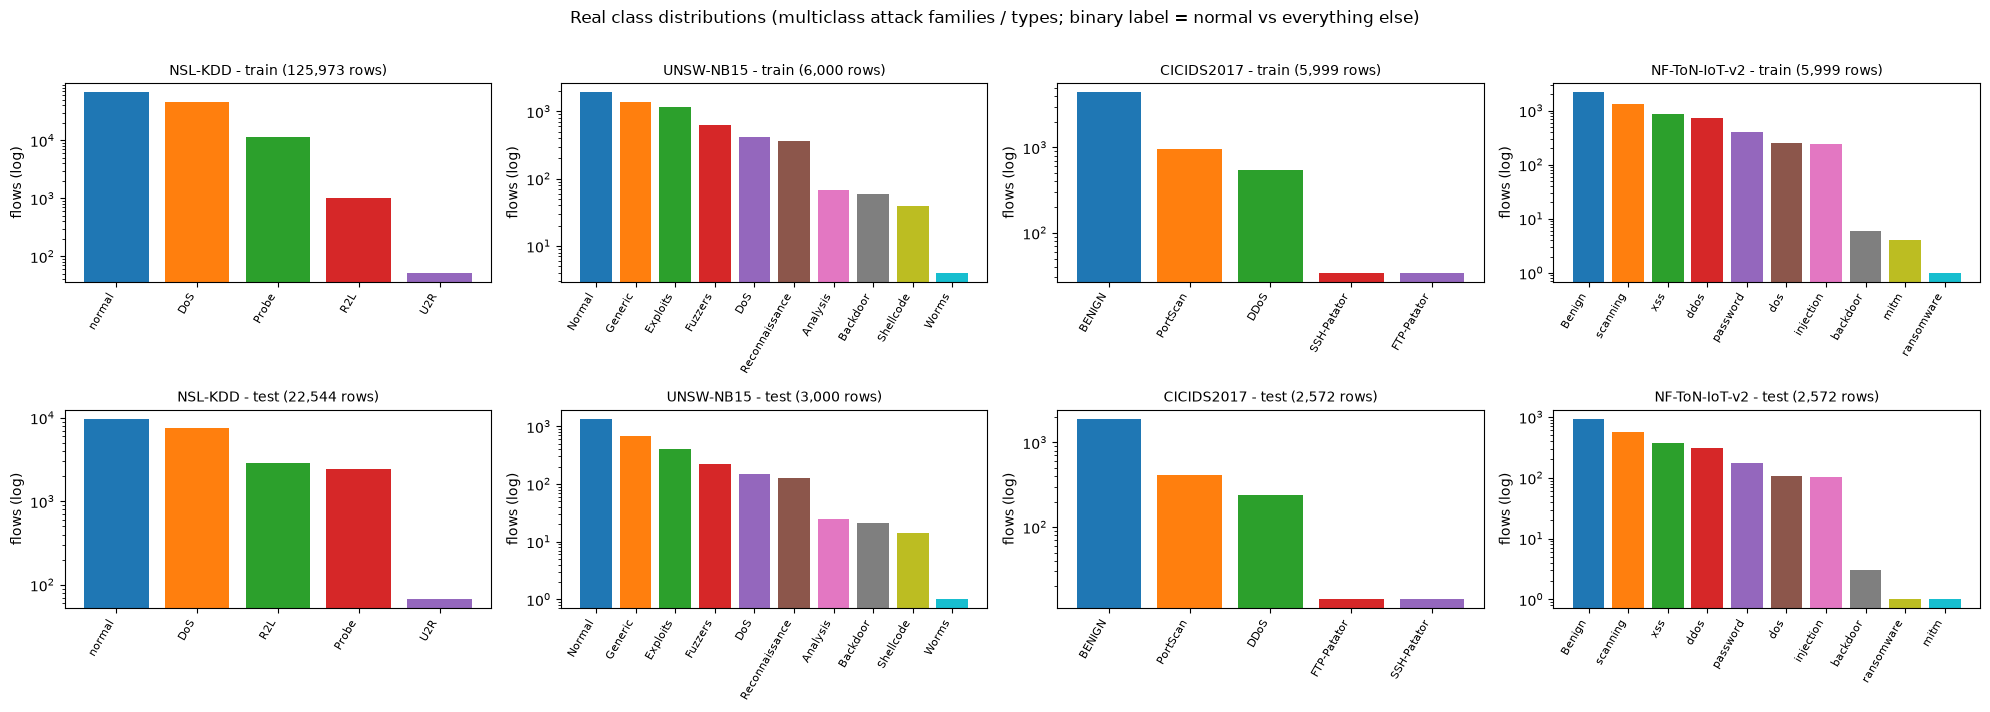

In [8]:
# ---- class distributions (bar charts of the REAL labels: attack family / attack type, train and test)
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, (name, v) in enumerate(DS.items()):
    D = v["D"]
    for i, (split, y) in enumerate((("train", D["ytr_cls"]), ("test", D["yte_cls"]))):
        vc = pd.Series(y).value_counts()
        ax = axes[i, j]
        ax.bar(range(len(vc)), vc.values, color=plt.cm.tab10(np.arange(len(vc)) % 10))
        ax.set_xticks(range(len(vc))); ax.set_xticklabels(vc.index, rotation=60, ha="right", fontsize=8)
        ax.set_yscale("log"); ax.set_title(f"{name} - {split} ({len(y):,} rows)", fontsize=10); ax.set_ylabel("flows (log)")
plt.suptitle("Real class distributions (multiclass attack families / types; binary label = normal vs everything else)", y=1.01)
plt.tight_layout(); plt.show()


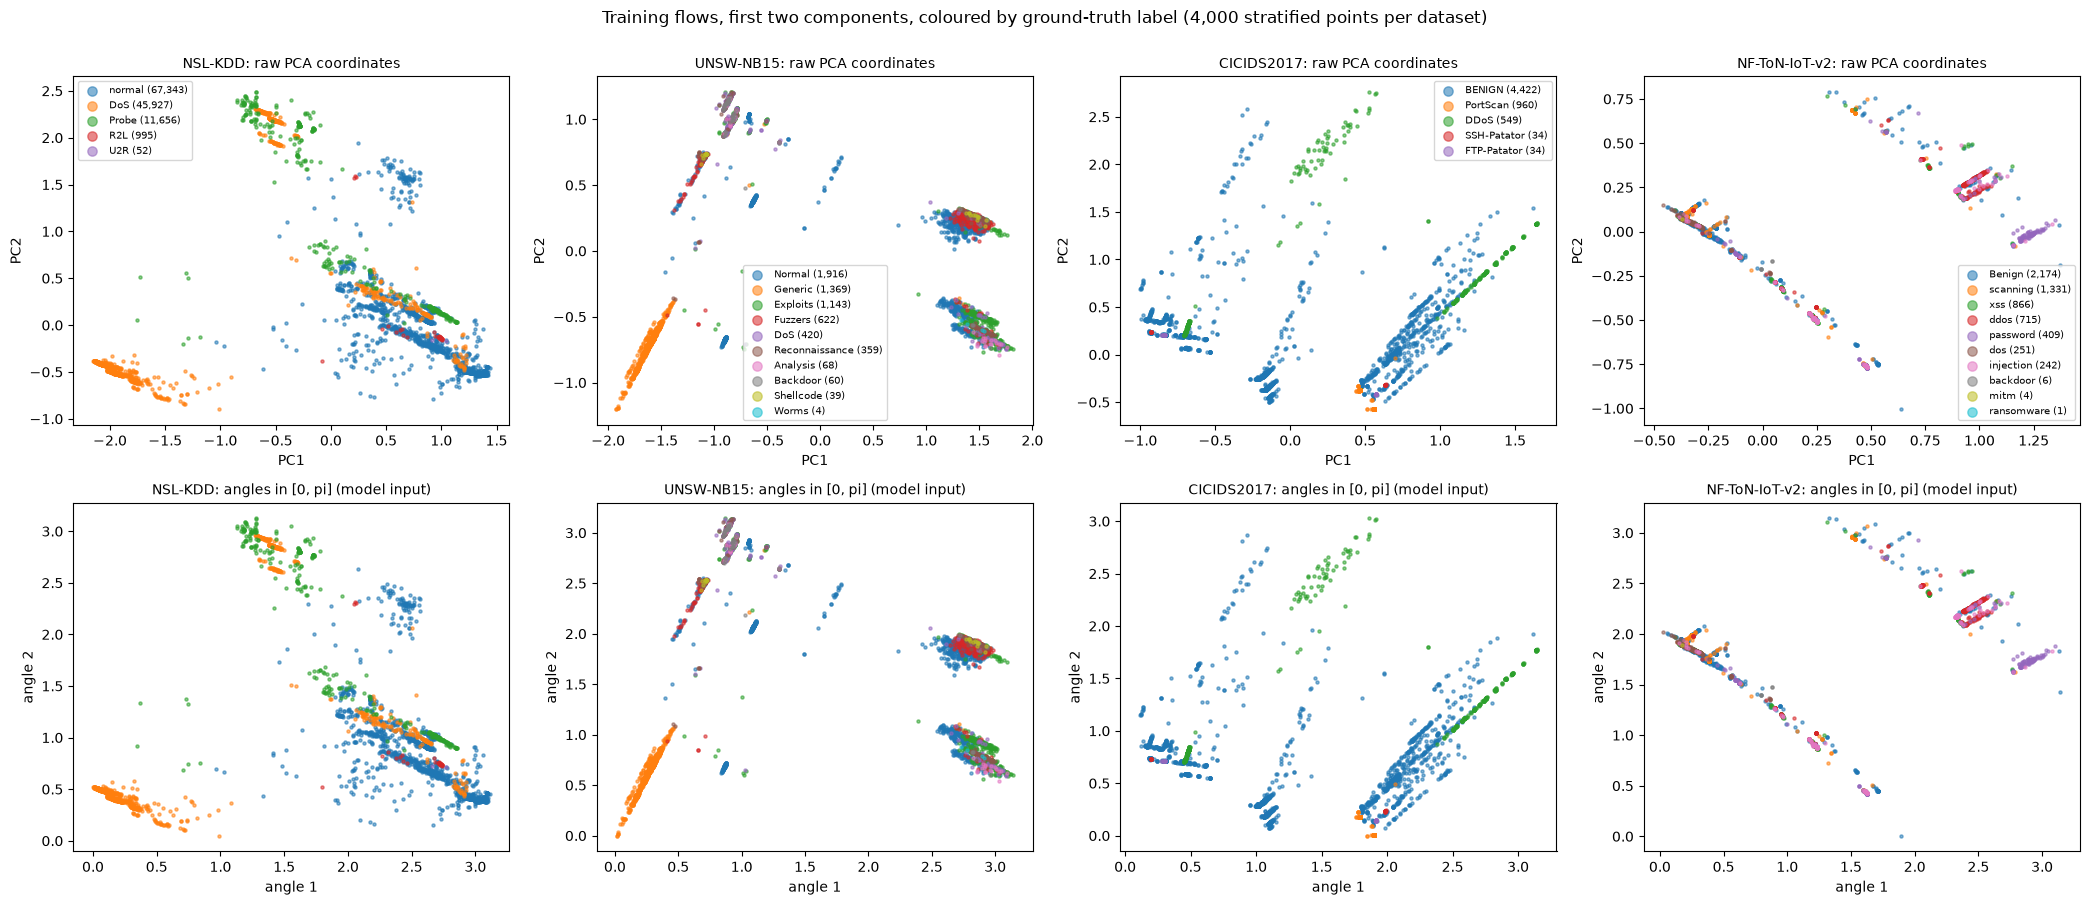

In [9]:
# ---- 2-D scatter of REAL training observations coloured by ground-truth class.
# Left: raw PCA coordinates (PCA fitted on the training split). Right: the same two coordinates after the
# [0, pi] scaling that the angle-encoded quantum models actually receive ("first two angles").
def class_colors(labels):
    uniq = list(pd.Series(labels).value_counts().index)
    return {c: plt.cm.tab10(i % 10) for i, c in enumerate(uniq)}

fig, axes = plt.subplots(2, 4, figsize=(21, 9))
for j, (name, v) in enumerate(DS.items()):
    D, V = v["D"], v["V"]
    sub = stratified_idx(D["ytr"], min(4000, len(D["ytr"])), SEED)
    cols = class_colors(D["ytr_cls"])
    for i, (X, ttl, xl, yl) in enumerate(((V["P_tr"], "raw PCA coordinates", "PC1", "PC2"),
                                          (V["Q_tr"], "angles in [0, pi] (model input)", "angle 1", "angle 2"))):
        ax = axes[i, j]
        for c in cols:
            m = D["ytr_cls"][sub] == c
            ax.scatter(X[sub][m, 0], X[sub][m, 1], s=5, alpha=0.55, color=cols[c], label=f"{c} ({int((D['ytr_cls']==c).sum()):,})")
        ax.set_title(f"{name}: {ttl}", fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
        if i == 0: ax.legend(markerscale=3, fontsize=7, loc="best")
plt.suptitle("Training flows, first two components, coloured by ground-truth label (4,000 stratified points per dataset)", y=1.0)
plt.tight_layout(); plt.show()


**Reading the plots.** NSL-KDD is dominated by normal traffic and DoS; Probe is smaller, and R2L/U2R are tiny (this is where the test-set distribution shift lives: R2L is far more common in
`KDDTest+`). In the first two components the attack families overlap strongly with normal traffic, which is why a model that sees only 8 components cannot reach the near-perfect numbers
quoted in the literature. UNSW-NB15 and NF-ToN-IoT-v2 have many small attack classes; CICIDS2017 (our slice) is easy: DDoS and PortScan separate cleanly. The paper reports exactly this ordering
of difficulty.

## 2. The two feature views and the PCA budget

`make_views` builds, **fitting every transform on the training split only**: the *same-budget* view (min-max -> PCA(n) -> min-max to [0, pi], test clipped) that feeds all quantum models
and the same-budget classical baselines, and the *full* view (min-max -> standardise every one-hot dimension) that gives the classical models their practical ceiling.
The paper's Table 2 reports how much variance 8 principal components keep; the exploration section above printed ours.

In [10]:
Dn, Vn = DS["NSL-KDD"]["D"], DS["NSL-KDD"]["V"]          # NSL-KDD raw data and feature views (fitted on the training split only)
ytr, yte = Dn["ytr"], Dn["yte"]
print(f"NSL-KDD: train {Vn['Q_tr'].shape} angles / {Vn['F_tr'].shape} full; test {Vn['Q_te'].shape} / {Vn['F_te'].shape}; PCA(8) explained variance {Vn['evr']:.3f}")


NSL-KDD: train (125973, 8) angles / (125973, 122) full; test (22544, 8) / (22544, 122); PCA(8) explained variance 0.841


## 3. The authors' harness and two equivalence checks

We import the authors' `quantum_model.py` (Hybrid model, `QuantumConfig`, IQP/ZZ feature map, `QuantumKernelSVM`), `attribution.py` (matched MLP, random-feature kernel), `evaluation.py`
(metrics incl. TPR@FPR and ECE, McNemar, paired bootstrap) and `baselines.py` (tuned classical models). Two things are ours, so we **prove they do not change the maths**:

1. **Simulator.** `lightning.qubit` evaluates a `TorchLayer` one sample at a time; PennyLane's `default.qubit` supports parameter *broadcasting*. The same QNode and weights give the same outputs (asserted below).
2. **Kernel.** The authors' `QuantumKernelSVM` runs one circuit per pair of samples (O(N^2) QNode calls). We compute the same Gram matrix from batched statevectors, `K = |<phi(x)|phi(x')>|^2`
   (and the projected kernel from per-qubit `<X>,<Y>,<Z>`), and assert agreement with the authors' implementation on sample pairs.

In [11]:
import time, torch, torch.nn as nn
import pennylane as qml
import quantum_model as qm            # authors' module (pinned commit): HybridQNN, QuantumConfig, zz_feature_map, ...
import attribution as attr            # authors' module: RandomFeatureKernelSVM, matched_mlp_for_qnn, ...
import evaluation as ev               # authors' module: metrics, paired_bootstrap, mcnemar_test, paired_t_test
import baselines as bl                # authors' module: tuned classical baselines

# CHOICE: simulator back-end. The authors' default (lightning.qubit + adjoint) evaluates a TorchLayer one sample
# at a time, which is ~10x slower than PennyLane's *broadcast* default.qubit (+ torch back-prop) on a CPU laptop.
# The circuit is the same QNode built by qm.build_vqc_qnode; only the simulator changes (checked below).
TINY_P = 1e-8      # a noise strength below this is treated as "layer-wise circuit, no channel" (see the noise section)
def _fast_make_device(n_qubits, noise=None, prefer="cpu"):
    nz = qm.normalize_noise(noise)
    if nz is not None and nz["p"] >= TINY_P:
        return qml.device("default.mixed", wires=n_qubits), "default.mixed"
    return qml.device("default.qubit", wires=n_qubits), "default.qubit"
qm.make_device = _fast_make_device

# CHOICE: in the authors' code a *noisy* circuit applies the ansatz one layer at a time (so a channel can follow every layer),
# whereas the noiseless circuit applies the whole StronglyEntanglingLayers template at once; the two differ slightly in the CNOT
# range of layers >= 2. To compare noise strengths like with like, the noise study trains its "noiseless" reference with the same
# layer-by-layer circuit and a channel strength of 1e-9, which we turn into "no channel, cheap default.qubit simulator".
_orig_apply_noise = qm._apply_noise
def _apply_noise_or_skip(noise, n_qubits):
    if noise is None or noise["p"] < TINY_P:
        return
    _orig_apply_noise(noise, n_qubits)
qm._apply_noise = _apply_noise_or_skip
LAYERWISE_NOISELESS = {"type": "depolarizing", "p": 1e-9}

# CHOICE: the authors' search grids offer 200-800 trees, which is far too slow for a CPU class demo. We keep their grids
# (depth, learning rate, leaf sizes, ...) but cap the ensemble size at MAX_TREES during the search as well as at refit.
def _cap_trees(space_fn):
    def capped():
        sp = dict(space_fn())
        sp["n_estimators"] = sorted({MAX_TREES // 2, MAX_TREES})
        return sp
    return capped
bl._rf_space, bl._xgb_space = _cap_trees(bl._rf_space), _cap_trees(bl._xgb_space)

def make_hybrid(n_qubits, n_layers, encoding="angle", ansatz="strongly_entangling", noise=None):
    cfg = qm.QuantumConfig(in_dim=n_qubits, n_qubits=n_qubits, n_layers=n_layers, encoding=encoding,
                           ansatz=ansatz, diff_method="backprop", noise=noise)
    return qm.HybridQNN(in_dim=n_qubits, config=cfg)

def count_params(m):
    return int(sum(p.numel() for p in m.parameters() if p.requires_grad))

def train_torch(model, Xtr, ytr, epochs, batch_size, lr, seed, weight_decay=0.0, log=None, class_weight=True):
    """Mini-batch Adam loop with balanced-class cross-entropy (same recipe as the authors' runner)."""
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    w = None
    if class_weight:
        cls, cnt = np.unique(ytr, return_counts=True)
        w = torch.tensor(cnt.sum() / (len(cls) * cnt), dtype=torch.float32)
    lossf = nn.CrossEntropyLoss(weight=w)
    X = torch.tensor(Xtr, dtype=torch.float32); y = torch.tensor(ytr, dtype=torch.long)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=g); tot = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad(); loss = lossf(model(X[idx]), y[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / len(X))
        if log and (ep == 0 or (ep + 1) % max(1, epochs // 4) == 0):
            print(f"      epoch {ep+1:>3}/{epochs} loss={hist[-1]:.4f} ({time.time()-t0:.0f}s)", flush=True)
    return hist, time.time() - t0

@torch.no_grad()
def predict_torch(model, X, chunk=4096):
    model.eval(); P = []
    for i in range(0, len(X), chunk):
        P.append(torch.softmax(model(torch.tensor(X[i:i + chunk], dtype=torch.float32)), 1)[:, 1].numpy())
    p = np.concatenate(P)
    return (p >= 0.5).astype(int), p

def score(y, pred, proba):
    """Authors' metric suite (accuracy ... F1, DR, FPR, ROC-AUC, AUPRC, TPR@0.1%/1% FPR, Brier, ECE)."""
    return ev.metrics(y, pred, proba)

# ----------------------------- kernel models (exact statevector kernels) -----------------------------
def _state_qnode(n_qubits, encoding):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="numpy")
    def circuit(x):
        if encoding == "iqp":
            qm.zz_feature_map(x, n_qubits, n_repeats=2)          # authors' IQP / ZZ feature map
        else:
            qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
        return qml.state()
    return circuit

def _proj_qnode(n_qubits):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="numpy")
    def circuit(x):
        qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
        return [qml.expval(op(w)) for w in range(n_qubits) for op in (qml.PauliX, qml.PauliY, qml.PauliZ)]
    return circuit

def feature_states(circuit, X, chunk=2048, proj=False):
    """Batched (broadcast) evaluation of the feature-map circuit on all rows of X."""
    out = []
    for i in range(0, len(X), chunk):
        a = np.asarray(circuit(np.asarray(X[i:i + chunk], dtype=np.float64)))
        out.append(a.T if proj else a)          # the projected circuit returns 3q arrays of shape (chunk,)
    return np.concatenate(out)

class FastQuantumKernelSVM:
    """QSVM = authors' QuantumKernelSVM maths, evaluated with batched statevectors.

    fidelity : K(x,x') = |<phi(x')|phi(x)>|^2  with the IQP (ZZ) feature map, SVC(kernel='precomputed')
    projected: K = exp(-gamma ||rho(x)-rho(x')||^2), rho = per-qubit <X>,<Y>,<Z> of the angle-encoded state
    """
    def __init__(self, n_qubits=8, encoding="iqp", kernel="fidelity", gamma=1.0, C=1.0):
        from sklearn.svm import SVC
        self.n, self.encoding, self.kernel, self.gamma = n_qubits, encoding, kernel, gamma
        self.svc = SVC(kernel="precomputed", C=C)
        self.circ = _state_qnode(n_qubits, encoding) if kernel == "fidelity" else _proj_qnode(n_qubits)
    def _feat(self, X):
        return feature_states(self.circ, X, proj=(self.kernel == "projected"))
    def _gram(self, FA, FB):
        if self.kernel == "fidelity":
            return np.abs(FA.conj() @ FB.T) ** 2
        sq = (FA ** 2).sum(1)[:, None] + (FB ** 2).sum(1)[None, :] - 2 * FA @ FB.T
        return np.exp(-self.gamma * np.maximum(sq, 0))
    def fit(self, X, y):
        self.Ftr = self._feat(X); self.svc.fit(self._gram(self.Ftr, self.Ftr), y); return self
    def decision_function(self, X, chunk=2000):
        out = []
        for i in range(0, len(X), chunk):
            out.append(self.svc.decision_function(self._gram(self._feat(X[i:i + chunk]), self.Ftr)))
        return np.concatenate(out)
    def predict(self, X):
        return (self.decision_function(X) > 0).astype(int)


In [12]:
RES = {}      # RES[key] = {"seed": [...], "m": [metric dicts], "proba": [P(attack) or score arrays], "pred": [...], "time": [...]}
MODELS = {}   # reference-seed trained torch models (kept for the circuit drawings and the noise study)

def record(key, seed, y, pred, proba, secs, probabilistic=True, idx=None):
    """Store one (model, seed) result. `idx` restricts the metrics to a fixed test subset."""
    sel = slice(None) if idx is None else idx
    m = score(y[sel], pred[sel], proba[sel])
    if not probabilistic:                 # kernel SVM / random-feature margins are not probabilities
        m["brier"] = m["ece"] = float("nan")
    m["secs"] = round(float(secs), 1)
    r = RES.setdefault(key, dict(seed=[], m=[], proba=[], pred=[]))
    r["seed"].append(seed); r["m"].append(m); r["proba"].append(proba); r["pred"].append(pred)
    return m

def summarize(keys, metrics=("f1", "roc_auc", "auprc", "tpr_at_1pct_fpr", "tpr_at_0.1pct_fpr", "ece", "false_positive_rate", "secs")):
    rows = []
    for k in keys:
        r = RES[k]; row = {"model": k, "n_seeds": len(r["seed"])}
        for met in metrics:
            vals = np.array([m.get(met, np.nan) for m in r["m"]], dtype=float)
            row[met] = f"{np.nanmean(vals):.3f}" + (f" +/- {np.nanstd(vals, ddof=1):.3f}" if len(vals) > 1 else "")
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

def mean_metric(key, met):
    return float(np.nanmean([m[met] for m in RES[key]["m"]]))

# ------------------------------------------------------------------ classical sklearn baselines
def run_sklearn_baseline(name, key, Xtr, ytr, Xte, yte, seeds, tune_seed=SEED, cap=None, verbose=True):
    """Tune once on the training split (randomized search, stratified CV, F1), refit per seed, score on the test split."""
    t0 = time.time()
    tr = bl.tune_sklearn_baseline(name, Xtr, ytr, seed=tune_seed, n_iter=TUNE_ITER, cv_folds=TUNE_CV,
                                  search_subsample=TUNE_ROWS, svm_subsample=min(TUNE_ROWS, SVM_CAP), verbose=0)
    params = dict(tr.best_params)
    if "n_estimators" in params:                      # CHOICE: cap the ensemble size to keep the CPU run short
        params["n_estimators"] = min(params["n_estimators"], MAX_TREES)
    if verbose: print(f"  [{key}] tuned in {time.time()-t0:.0f}s: cv-F1={tr.cv_best_f1:.3f} params={params}", flush=True)
    for s in seeds:
        ts = time.time()
        idx = stratified_idx(ytr, cap, s) if cap and cap < len(ytr) else np.arange(len(ytr))
        est = bl.fit_tuned_sklearn(name, params, Xtr[idx], ytr[idx], seed=s, svm_max_train=SVM_CAP)
        p = est.predict_proba(Xte)[:, 1]
        record(key, s, yte, (p >= 0.5).astype(int), p, time.time() - ts)
    return tr

# CHOICE: the tuned MLP / 1D-CNN hyper-parameters are the authors' released best configurations
# (configs/classical_tuned_nslkdd.yaml of the pinned commit); only the epoch budget is ours.
NN_HP = {"full": {"mlp": dict(hidden=(128, 64), dropout=0.3, lr=1e-3), "cnn1d": dict(channels=(32, 64), kernel=5, dropout=0.3, lr=5e-4)},
         "sb":   {"mlp": dict(hidden=(128, 64, 32), dropout=0.3, lr=1e-3), "cnn1d": dict(channels=(64, 128), kernel=3, dropout=0.4, lr=5e-4)}}

def run_torch_baseline(kind, view, key, Xtr, ytr, Xte, yte, seeds, cap):
    hp = NN_HP[view][kind]
    for s in seeds:
        idx = stratified_idx(ytr, cap, s) if cap and cap < len(ytr) else np.arange(len(ytr))
        torch.manual_seed(s)
        model = bl.build_torch_baseline(kind, Xtr.shape[1], hp)
        _, secs = train_torch(model, Xtr[idx], ytr[idx], NN_EPOCHS, NN_BATCH, hp["lr"], s, class_weight=CLASS_WEIGHT)
        pred, p = predict_torch(model, Xte)
        record(key, s, yte, pred, p, secs)

# ------------------------------------------------------------------ quantum models
def run_hybrid(key, Vq, ytr, yte, q, layers, enc, ansatz, seeds, n_train, epochs, idx=None, keep=True, verbose=True):
    """Train the authors' HybridQNN (classical Linear+Tanh -> VQC -> Linear) for each seed and score it."""
    for s in seeds:
        sub = stratified_idx(ytr, n_train, s)
        torch.manual_seed(s); np.random.seed(s)
        model = make_hybrid(q, layers, enc, ansatz)
        if verbose and s == seeds[0]:
            print(f"  [{key}] {q} qubits, {layers} layers, {enc}/{ansatz}: {count_params(model)} trainable parameters, "
                  f"{len(sub)} training rows x {epochs} epochs", flush=True)
        _, secs = train_torch(model, Vq["Q_tr"][sub], ytr[sub], epochs, BATCH, LR, s, log=verbose and s == seeds[0], class_weight=CLASS_WEIGHT)
        Xte = Vq["Q_te"] if idx is None else Vq["Q_te"][idx]
        t1 = time.time()
        pred, p = predict_torch(model, Xte)
        yt = yte if idx is None else yte[idx]
        record(key, s, yt, pred, p, secs + time.time() - t1)
        if s == seeds[0] and keep: MODELS[key] = model
    return RES[key]

def run_matched_mlp(key, ref_model, Vq, ytr, yte, seeds, n_train, epochs, wd, idx=None):
    """Classical MLP whose parameter count >= the hybrid's (authors' attribution.matched_mlp_for_qnn)."""
    q = Vq["Q_tr"].shape[1]
    for s in seeds:
        sub = stratified_idx(ytr, n_train, s)
        torch.manual_seed(s)
        mlp, info = attr.matched_mlp_for_qnn(ref_model, q)
        _, secs = train_torch(mlp, Vq["Q_tr"][sub], ytr[sub], epochs, BATCH, LR, s, weight_decay=wd, class_weight=CLASS_WEIGHT)
        Xte = Vq["Q_te"] if idx is None else Vq["Q_te"][idx]
        pred, p = predict_torch(mlp, Xte)
        record(key, s, yte if idx is None else yte[idx], pred, p, secs)
    return info

def run_rf_kernel(key, method, Vq, ytr, yte, seeds, n_train, idx=None, n_components=512, gamma=1.0):
    for s in seeds:
        sub = stratified_idx(ytr, n_train, s)
        t0 = time.time()
        m = attr.RandomFeatureKernelSVM(method=method, n_components=n_components, gamma=gamma, seed=s).fit(Vq["Q_tr"][sub], ytr[sub])
        Xte = Vq["Q_te"] if idx is None else Vq["Q_te"][idx]
        d = m.decision_function(Xte)
        record(key, s, yte if idx is None else yte[idx], (d > 0).astype(int), d, time.time() - t0, probabilistic=False)

def run_qsvm(key, encoding, kernel, Vq, ytr, yte, seeds, n_train, gamma=1.0, idx=None):
    for s in seeds:
        sub = stratified_idx(ytr, n_train, s)
        t0 = time.time()
        m = FastQuantumKernelSVM(Vq["Q_tr"].shape[1], encoding, kernel, gamma=gamma).fit(Vq["Q_tr"][sub], ytr[sub])
        Xte = Vq["Q_te"] if idx is None else Vq["Q_te"][idx]
        d = m.decision_function(Xte)
        record(key, s, yte if idx is None else yte[idx], (d > 0).astype(int), d, time.time() - t0, probabilistic=False)


In [13]:
# ---- Equivalence checks: (1) fast simulator == the authors' lightning.qubit model; (2) batched kernel == circuit-by-circuit kernel
try:                                     # lightning is only needed for this check
    import importlib; importlib.import_module("pennylane_lightning")
    have_lightning = True
except Exception:
    have_lightning = False
print("lightning.qubit available:", have_lightning)
if have_lightning:
    torch.manual_seed(0)
    fast = make_hybrid(6, 2, "angle", "strongly_entangling")
    def _lightning_device(n_qubits, noise=None, prefer="cpu"):
        return qml.device("lightning.qubit", wires=n_qubits), "lightning.qubit"
    qm.make_device = _lightning_device
    ref = qm.HybridQNN(in_dim=6, config=qm.QuantumConfig(in_dim=6, n_qubits=6, n_layers=2, encoding="angle",
                                                        ansatz="strongly_entangling", diff_method="adjoint"))
    qm.make_device = _fast_make_device
    ref.load_state_dict(fast.state_dict())
    xb = torch.rand(8, 6) * np.pi
    with torch.no_grad():
        a, b = fast(xb), ref(xb)
    print("max |default.qubit - lightning.qubit| on the model output:", float((a - b).abs().max()))
    assert torch.allclose(a, b, atol=1e-5), "simulator back-ends disagree"
    t = time.time()
    for _ in range(2):
        fast.zero_grad(); fast(xb.repeat(4, 1)).sum().backward()
    t_fast = (time.time() - t) / 2
    t = time.time()
    for _ in range(2):
        ref.zero_grad(); ref(xb.repeat(4, 1)).sum().backward()
    t_ref = (time.time() - t) / 2
    print(f"one forward+backward on 32 samples (6 qubits): default.qubit+broadcast {t_fast:.2f}s vs lightning.qubit+adjoint (authors) {t_ref:.2f}s")

# (2) kernel equivalence on a few pairs of NSL-KDD angle vectors
Xk = Vn["Q_tr"][:6].astype(np.float64)
fast_k = FastQuantumKernelSVM(N_QUBITS, "iqp", "fidelity")
F = fast_k._feat(Xk); Kfast = fast_k._gram(F, F)
ref_k = qm.QuantumKernelSVM(n_qubits=N_QUBITS, encoding="iqp", kernel="fidelity", device="cpu")
Kref = np.array([[ref_k._fidelity(a, b) for b in Xk] for a in Xk])
print("max |K_batched - K_authors| (IQP fidelity kernel, 6x6 pairs):", float(np.abs(Kfast - Kref).max()))
assert np.allclose(Kfast, Kref, atol=1e-8)
fast_p = FastQuantumKernelSVM(N_QUBITS, "angle", "projected")
Fp = fast_p._feat(Xk); Kp = fast_p._gram(Fp, Fp)
ref_p = qm.QuantumKernelSVM(n_qubits=N_QUBITS, encoding="angle", kernel="projected", device="cpu")
Kpref = ref_p._kernel_matrix(Xk, Xk)
print("max |K_batched - K_authors| (angle projected kernel):", float(np.abs(Kp - Kpref).max()))
assert np.allclose(Kp, Kpref, atol=1e-8)


lightning.qubit available: True


max |default.qubit - lightning.qubit| on the model output: 2.9802322387695312e-08


one forward+backward on 32 samples (6 qubits): default.qubit+broadcast 0.10s vs lightning.qubit+adjoint (authors) 0.55s


max |K_batched - K_authors| (IQP fidelity kernel, 6x6 pairs): 1.3322676295501878e-15


max |K_batched - K_authors| (angle projected kernel): 5.329070518200751e-15


## 4. Classical baselines on NSL-KDD (full view and same-budget view)

Each model is hyper-parameter-searched with stratified cross-validation **on the training split only** (the authors' `tune_sklearn_baseline`), re-fit per seed and scored once on `KDDTest+`.
Cost-sensitive learning (balanced class weights / `scale_pos_weight`) is used instead of SMOTE, as in the paper. "Same-budget" models receive exactly the 8 angles the 8-qubit quantum models receive.

In [14]:
C_SEEDS_FULLVIEW = C_SEEDS[:3]          # CHOICE: fewer seeds for the expensive full-dimensional (122-d) view
NN_SEEDS = C_SEEDS[:2] if FAST_MODE else C_SEEDS[:3]
t0 = time.time()
print("Tuning tree/kernel baselines (randomized search, stratified CV on the TRAIN split only) ...")
for name, lab in (("random_forest", "RF"), ("xgboost", "XGBoost"), ("svm_rbf", "SVM-RBF")):
    for view, (Xa, Xb, seeds) in {"same-budget": (Vn["Q_tr"], Vn["Q_te"], C_SEEDS), "full": (Vn["F_tr"], Vn["F_te"], C_SEEDS_FULLVIEW)}.items():
        run_sklearn_baseline(name, f"{lab} [{view}]", Xa, ytr, Xb, yte, seeds, cap=C_TRAIN_CAP)
        print(f"    done {lab} [{view}] at {time.time()-t0:.0f}s", flush=True)
for kind, lab in (("mlp", "Tuned MLP"), ("cnn1d", "1D-CNN")):
    run_torch_baseline(kind, "sb", f"{lab} [same-budget]", Vn["Q_tr"], ytr, Vn["Q_te"], yte, NN_SEEDS, NN_CAP)
    run_torch_baseline(kind, "full", f"{lab} [full]", Vn["F_tr"], ytr, Vn["F_te"], yte, NN_SEEDS[:2], NN_CAP)
    print(f"    done {lab} at {time.time()-t0:.0f}s", flush=True)
CLASSICAL_KEYS = [k for k in RES]
print(summarize(CLASSICAL_KEYS).to_string())


Tuning tree/kernel baselines (randomized search, stratified CV on the TRAIN split only) ...


  [RF [same-budget]] tuned in 9s: cv-F1=0.981 params={'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}


    done RF [same-budget] at 15s


  [RF [full]] tuned in 8s: cv-F1=0.992 params={'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20}


    done RF [full] at 28s


...

  [SVM-RBF [full]] tuned in 16s: cv-F1=0.987 params={'gamma': 'scale', 'C': 100.0}


    done SVM-RBF [full] at 110s


    done Tuned MLP at 139s


    done 1D-CNN at 256s


                         n_seeds               f1          roc_auc            auprc  tpr_at_1pct_fpr tpr_at_0.1pct_fpr              ece false_positive_rate              secs
model                                                                                                                                                                        
RF [same-budget]               2  0.767 +/- 0.008  0.954 +/- 0.001  0.959 +/- 0.001  0.475 +/- 0.011   0.072 +/- 0.002  0.189 +/- 0.004     0.027 +/- 0.001   2.950 +/- 0.212
RF [full]                      2  0.766 +/- 0.000  0.963 +/- 0.000  0.968 +/- 0.001  0.436 +/- 0.008   0.381 +/- 0.011  0.184 +/- 0.001     0.028 +/- 0.001   2.850 +/- 0.071
XGBoost [same-budget]          2  0.787 +/- 0.003  0.958 +/- 0.004  0.964 +/- 0.003  0.437 +/- 0.014   0.329 +/- 0.031  0.186 +/- 0.000     0.029 +/- 0.000   0.850 +/- 0.071
XGBoost [full]                 2  0.761 +/- 0.003  0.961 +/- 0.005  0.965 +/- 0.005  0.397 +/- 0.013   0.179 +/- 0.044  0.211 +/- 

## 5. Quantum models on NSL-KDD

*Hybrid VQC* = `Linear(8 -> 8) -> Tanh -> circuit -> Linear(8 -> 2)`, trained end to end with Adam (lr 0.005, batch 64, balanced cross-entropy). *QSVM* = a quantum kernel fed to `SVC(kernel="precomputed")`.
Metrics are the paper's: F1, ROC-AUC, AUPRC, TPR at 0.1 % / 1 % false-positive rate, Brier score and expected calibration error (ECE). Kernel margins are not probabilities, so their Brier/ECE are left undefined (as in the authors' harness).

In [15]:
# ---- NSL-KDD quantum models on the same-budget input (8 PCA components -> 8 angles in [0, pi])
t0 = time.time()
L2_GRID = (0.0, 1e-3) if FAST_MODE else (0.0, 1e-4, 1e-3, 1e-2)       # regularisation sweep of the matched MLP
HYBRIDS = [("Hyb-Angle-SE q8", "angle", "strongly_entangling"), ("Hyb-IQP-SE q8", "iqp", "strongly_entangling")]
if not FAST_MODE:
    HYBRIDS += [("Hyb-Angle-BE q8", "angle", "basic_entangler"), ("Hyb-Reupload-SE q8", "reupload", "strongly_entangling")]
for key, enc, ans in HYBRIDS:
    run_hybrid(key, Vn, ytr, yte, N_QUBITS, N_LAYERS, enc, ans, Q_SEEDS, Q_TRAIN, Q_EPOCHS)
    print(f"    done {key} at {time.time()-t0:.0f}s: F1={mean_metric(key,'f1'):.3f} AUPRC={mean_metric(key,'auprc'):.3f} TPR@1%FPR={mean_metric(key,'tpr_at_1pct_fpr'):.3f}", flush=True)

# quantum-kernel SVMs: exact statevector kernels (checked against the authors' circuit-by-circuit kernel above)
run_qsvm("QSVM-IQP (fidelity) q8", "iqp", "fidelity", Vn, ytr, yte, Q_SEEDS, QSVM_N)
run_qsvm("QSVM-Angle (projected) q8", "angle", "projected", Vn, ytr, yte, Q_SEEDS, QSVM_N)
print(f"    done QSVMs at {time.time()-t0:.0f}s")
QUANTUM8 = [k for k, _, _ in HYBRIDS] + ["QSVM-IQP (fidelity) q8", "QSVM-Angle (projected) q8"]
print(summarize(QUANTUM8).to_string())


  [Hyb-Angle-SE q8] 8 qubits, 3 layers, angle/strongly_entangling: 162 trainable parameters, 600 training rows x 6 epochs


      epoch   1/6 loss=0.6906 (3s)


      epoch   2/6 loss=0.6674 (6s)


      epoch   3/6 loss=0.6391 (10s)


      epoch   4/6 loss=0.6002 (13s)


...

      epoch   4/6 loss=0.5916 (23s)


      epoch   5/6 loss=0.5552 (29s)


      epoch   6/6 loss=0.5113 (35s)


    done Hyb-IQP-SE q8 at 186s: F1=0.708 AUPRC=0.916 TPR@1%FPR=0.311


    done QSVMs at 324s
                           n_seeds               f1          roc_auc            auprc  tpr_at_1pct_fpr tpr_at_0.1pct_fpr              ece false_positive_rate              secs
model                                                                                                                                                                          
Hyb-Angle-SE q8                  2  0.719 +/- 0.004  0.928 +/- 0.004  0.943 +/- 0.004  0.511 +/- 0.047   0.169 +/- 0.023  0.242 +/- 0.001     0.024 +/- 0.004  32.700 +/- 0.707
Hyb-IQP-SE q8                    2  0.708 +/- 0.022  0.900 +/- 0.026  0.916 +/- 0.020  0.311 +/- 0.160   0.167 +/- 0.061  0.276 +/- 0.018     0.069 +/- 0.017  59.800 +/- 3.111
QSVM-IQP (fidelity) q8           2  0.631 +/- 0.013  0.944 +/- 0.010  0.955 +/- 0.006  0.436 +/- 0.029   0.247 +/- 0.126      nan +/- nan     0.016 +/- 0.003  38.850 +/- 2.192
QSVM-Angle (projected) q8        2  0.745 +/- 0.001  0.885 +/- 0.004  0.916 +/- 0.004  0.428 +/- 

### 5.1 Qubit-count ablation

The paper's most interesting result is that the *small* 4-qubit hybrid is the one that wins at the strict 1 % FPR point, while a 12-qubit hybrid loses. We train the angle-encoded strongly-entangling hybrid with 4, 8 and 12 qubits
(PCA dimension = qubit count). The 12-qubit model is expensive to simulate, so it uses a smaller budget and all three widths are compared on one fixed stratified test subset.

In [16]:
# ---- qubit-count ablation of the angle-encoded hybrid VQC (4 / 8 / 12 qubits), evaluated on ONE fixed stratified test subset
ABL_IDX = stratified_idx(yte, ABL_TEST_N, SEED)
VIEWS = {N_QUBITS: Vn}
for q in ABL_QUBITS:
    if q not in VIEWS:
        VIEWS[q] = make_views(Dn, n_qubits=q, seed=SEED)
    print(f"  {q} qubits: PCA explained variance of the {q} components = {VIEWS[q]['evr']:.3f}")
t0 = time.time()
for q in ABL_QUBITS:
    key = f"Hyb-Angle-SE q{q}"
    if q == 4:      # cheap: full test set
        run_hybrid(key, VIEWS[q], ytr, yte, q, N_LAYERS, "angle", "strongly_entangling", Q_SEEDS, Q_TRAIN, Q_EPOCHS)
    elif q == 12:   # expensive: smaller training budget, test subset only (12-qubit state = 4096 amplitudes)
        run_hybrid(key, VIEWS[q], ytr, yte, q, N_LAYERS, "angle", "strongly_entangling", Q_SEEDS[:1 if FAST_MODE else 2],
                   Q12_TRAIN, Q12_EPOCHS, idx=ABL_IDX)
    print(f"    done {key} at {time.time()-t0:.0f}s: F1={mean_metric(key,'f1'):.3f} TPR@1%FPR={mean_metric(key,'tpr_at_1pct_fpr'):.3f}", flush=True)


  4 qubits: PCA explained variance of the 4 components = 0.729
  8 qubits: PCA explained variance of the 8 components = 0.841


  12 qubits: PCA explained variance of the 12 components = 0.891
  [Hyb-Angle-SE q4] 4 qubits, 3 layers, angle/strongly_entangling: 66 trainable parameters, 600 training rows x 6 epochs


      epoch   1/6 loss=0.6894 (1s)


      epoch   2/6 loss=0.6585 (2s)


      epoch   3/6 loss=0.6192 (2s)


...

      epoch   3/6 loss=0.6588 (70s)


      epoch   4/6 loss=0.6267 (98s)


      epoch   5/6 loss=0.5801 (127s)


      epoch   6/6 loss=0.5213 (154s)


    done Hyb-Angle-SE q12 at 206s: F1=0.750 TPR@1%FPR=0.542


### 5.2 Matched classical controls

For every quantum model we build the paper's controls: a **parameter-matched MLP** (the smallest hidden width whose parameter count reaches the hybrid's, trained on the *same rows, same epochs*, with an L2 sweep that doubles as the regularisation sweep),
and a **random-feature kernel** (RBFSampler and Nystroem + linear SVM) as the classical surrogate of the quantum kernel. For the 4- and 12-qubit hybrids we also add a Random Forest on exactly their q-dimensional input.

In [17]:
# ---- matched classical controls (same front-end, same rows, same epochs) + random-feature kernel surrogates
t0 = time.time()
CONTROLS = {}          # quantum model key -> list of control keys that share its input
def add_controls(qkey, q, hybrid=True, idx=None, seeds=Q_SEEDS, n_train=Q_TRAIN, epochs=Q_EPOCHS):
    Vq = VIEWS[q]; ck = []; info = None
    if hybrid:
        for wd in L2_GRID:
            k = f"MatchedMLP l2={wd:g} <{qkey}>"
            if k not in RES:
                info = run_matched_mlp(k, MODELS[qkey], Vq, ytr, yte, seeds, n_train, epochs, wd, idx=idx)
            ck.append(k)
        if info: print(f"    matched MLP for {qkey}: {info['qnn_params']} hybrid parameters vs {info['matched_mlp_params']} MLP parameters (hidden={info['matched_hidden']})", flush=True)
    for method in ("rbf_sampler", "nystroem"):
        k = f"RFKernel-{method} <q{q}>"
        if k not in RES:
            run_rf_kernel(k, method, Vq, ytr, yte, seeds, RFK_N, idx=idx)
        ck.append(k)
    CONTROLS[qkey] = ck

for k, _, _ in HYBRIDS:
    add_controls(k, N_QUBITS)
add_controls("Hyb-Angle-SE q4", 4)
add_controls("Hyb-Angle-SE q12", 12, idx=ABL_IDX, seeds=Q_SEEDS[:1 if FAST_MODE else 2], n_train=Q12_TRAIN, epochs=Q12_EPOCHS)
for k in ("QSVM-IQP (fidelity) q8", "QSVM-Angle (projected) q8"):
    add_controls(k, N_QUBITS, hybrid=False)
# classical tree models on the *same* q-dimensional input as the 4- and 12-qubit hybrids (untuned-size forests, cheap)
for q in (4, 12):
    if q in ABL_QUBITS:
        Vq = VIEWS[q]
        for s in (Q_SEEDS if q == 4 else Q_SEEDS[:1 if FAST_MODE else 2]):
            sub = stratified_idx(ytr, C_TRAIN_CAP, s)
            rf = sklearn.ensemble.RandomForestClassifier(n_estimators=MAX_TREES, class_weight="balanced", random_state=s, n_jobs=2).fit(Vq["Q_tr"][sub], ytr[sub])
            Xq = Vq["Q_te"] if q == 4 else Vq["Q_te"][ABL_IDX]
            p = rf.predict_proba(Xq)[:, 1]
            record(f"RF <q{q}>", s, yte if q == 4 else yte[ABL_IDX], (p >= .5).astype(int), p, 0)
        CONTROLS[f"Hyb-Angle-SE q{q}"].append(f"RF <q{q}>")
print(f"controls done in {time.time()-t0:.0f}s")
print(summarize([k for k in RES if k.startswith(("MatchedMLP", "RFKernel", "RF <"))]).to_string())


    matched MLP for Hyb-Angle-SE q8: 162 hybrid parameters vs 162 MLP parameters (hidden=8)


    matched MLP for Hyb-IQP-SE q8: 162 hybrid parameters vs 162 MLP parameters (hidden=8)


    matched MLP for Hyb-Angle-SE q4: 66 hybrid parameters vs 67 MLP parameters (hidden=5)


    matched MLP for Hyb-Angle-SE q12: 290 hybrid parameters vs 299 MLP parameters (hidden=11)


controls done in 65s
                                        n_seeds               f1          roc_auc            auprc  tpr_at_1pct_fpr tpr_at_0.1pct_fpr              ece false_positive_rate             secs
model                                                                                                                                                                                      
MatchedMLP l2=0 <Hyb-Angle-SE q8>             2  0.739 +/- 0.031  0.919 +/- 0.000  0.938 +/- 0.004  0.457 +/- 0.050   0.159 +/- 0.106  0.186 +/- 0.027     0.070 +/- 0.007  0.600 +/- 0.000
MatchedMLP l2=0.001 <Hyb-Angle-SE q8>         2  0.739 +/- 0.030  0.919 +/- 0.000  0.938 +/- 0.004  0.454 +/- 0.044   0.159 +/- 0.106  0.184 +/- 0.029     0.072 +/- 0.009  0.650 +/- 0.071
RFKernel-rbf_sampler <q8>                     2  0.706 +/- 0.096  0.697 +/- 0.088  0.823 +/- 0.063  0.270 +/- 0.227   0.106 +/- 0.147      nan +/- nan     0.045 +/- 0.003  2.750 +/- 0.495
RFKernel-nystroem <q8>                 

## 6. The quantum-attribution audit

For each quantum variant and each metric we compare against the **best** matched/tuned classical control (direction-aware: lower ECE is better) and report the difference `delta = quantum - control`, the seed-level paired-t p-value,
and the *primary* p-value of a test on the shared test set (paired bootstrap for AUPRC / ROC-AUC / TPR@FPR, McNemar for F1, paired t for ECE). Benjamini-Hochberg q-values control the false-discovery rate over the whole family of comparisons.
For the QSVMs we additionally show the comparison with their *direct classical surrogate*, the random-feature kernel, which is the audit's sharpest test.

In [18]:
LOWER_BETTER = {"ece", "brier", "false_positive_rate"}
BOOT_METRICS = {"auprc", "roc_auc", "tpr_at_1pct_fpr", "tpr_at_0.1pct_fpr"}
AUDIT_METRICS = ["auprc", "roc_auc", "tpr_at_1pct_fpr", "tpr_at_0.1pct_fpr", "f1", "ece"]
_cache = {}

def per_seed(key, idx=None):
    """{seed: (metrics, score, pred)} of a stored result, optionally restricted to the fixed test subset idx."""
    ck = (key, None if idx is None else len(idx))
    if ck in _cache: return _cache[ck]
    out = {}
    probabilistic = not key.startswith(("QSVM", "RFKernel"))
    for s, p, pr in zip(RES[key]["seed"], RES[key]["proba"], RES[key]["pred"]):
        if idx is not None and len(p) == len(yte): p, pr = p[idx], pr[idx]
        y = yte if (idx is None or len(p) == len(yte)) else yte[idx]
        m = score(y, pr, p)
        if not probabilistic: m["brier"] = m["ece"] = float("nan")
        out[s] = (m, p, pr)
    _cache[ck] = out
    return out

def benjamini_hochberg(p):
    """Benjamini-Hochberg FDR-adjusted q-values."""
    p = np.asarray(p, dtype=float); n = len(p)
    order = np.argsort(p); ranked = p[order] * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1.0)
    return out

def audit_row(qkey, ckey, met, idx=None):
    Q, C = per_seed(qkey, idx), per_seed(ckey, idx)
    seeds = [s for s in Q if s in C]
    qv = np.array([Q[s][0][met] for s in seeds]); cv = np.array([C[s][0][met] for s in seeds])
    delta = float(np.nanmean(qv) - np.nanmean(cv))
    p_t = float("nan")
    if len(seeds) >= 2 and not np.allclose(qv - cv, (qv - cv)[0]):
        p_t = float(ev.paired_t_test(cv.tolist(), qv.tolist(), metric=met).t_p_value)
    ref = seeds[0]
    y = yte if idx is None else yte[idx]
    if met in BOOT_METRICS:
        p_main = ev.paired_bootstrap(y, C[ref][1], Q[ref][1], metric=met, n_boot=N_BOOT, seed=SEED).p_value; test = "paired bootstrap"
    elif met == "f1":
        p_main = ev.mcnemar_test(y, C[ref][2], Q[ref][2]).p_value; test = "McNemar"
    else:
        p_main, test = p_t, "paired t (seeds)"
    better = (delta < 0) if met in LOWER_BETTER else (delta > 0)
    return dict(metric=met, quantum=float(np.nanmean(qv)), control=float(np.nanmean(cv)), delta=delta,
                q_better="yes" if better and abs(delta) > 0.005 else ("tie" if abs(delta) <= 0.005 else "no"),
                p_seeds=p_t, p=p_main, test=test, n_seeds=len(seeds))

def best_control(qkey, met, pool, idx=None):
    best, bv = None, None
    for ck in pool:
        Q, C = per_seed(qkey, idx), per_seed(ck, idx)
        seeds = [s for s in Q if s in C]
        if not seeds: continue
        v = np.nanmean([C[s][0][met] for s in seeds])
        if np.isnan(v): continue
        if bv is None or (v < bv if met in LOWER_BETTER else v > bv): best, bv = ck, v
    return best

def run_audit(qkeys, pool_extra, idx_for=None, surrogate_for=None):
    rows = []
    for qk in qkeys:
        idx = (idx_for or {}).get(qk)
        pool = list(CONTROLS.get(qk, [])) + list(pool_extra)
        for met in AUDIT_METRICS:
            if met == "ece" and qk.startswith("QSVM"): continue      # kernel margins are not probabilities -> no calibration
            bc = best_control(qk, met, pool, idx)
            if bc:
                rows.append(dict(variant=qk, control_model=bc, kind="best control", **audit_row(qk, bc, met, idx)))
            if surrogate_for and qk in surrogate_for:      # direct classical surrogate of the quantum kernel
                sc = best_control(qk, met, surrogate_for[qk], idx)
                if sc and sc != bc:
                    rows.append(dict(variant=qk, control_model=sc, kind="surrogate (rf-kernel)", **audit_row(qk, sc, met, idx)))
    df = pd.DataFrame(rows)
    df["q_BH"] = benjamini_hochberg(df["p"].fillna(1.0).values)
    df["survives_FDR(q<0.05)"] = df["q_BH"] < 0.05
    return df


In [19]:
# ---- attribution audit: every quantum variant vs the BEST matched/tuned classical control (direction-aware, per metric)
SB_CLASSICAL = [k for k in CLASSICAL_KEYS if "[same-budget]" in k]
AUDIT_Q = ["QSVM-IQP (fidelity) q8", "QSVM-Angle (projected) q8", "Hyb-Angle-SE q4"] + [k for k, _, _ in HYBRIDS] + ["Hyb-Angle-SE q12"]
AUDIT_Q = list(dict.fromkeys(AUDIT_Q))
t0 = time.time()
AUDIT = run_audit(AUDIT_Q, SB_CLASSICAL, idx_for={"Hyb-Angle-SE q12": ABL_IDX},
                  surrogate_for={k: [c for c in CONTROLS[k] if c.startswith("RFKernel")] for k in ("QSVM-IQP (fidelity) q8", "QSVM-Angle (projected) q8")})
print(f"audit: {len(AUDIT)} comparisons in {time.time()-t0:.0f}s (bootstrap resamples = {N_BOOT})")
show = AUDIT.copy()
for c in ("quantum", "control", "delta"): show[c] = show[c].map(lambda v: f"{v:+.3f}" if c == "delta" else f"{v:.3f}")
for c in ("p_seeds", "p", "q_BH"): show[c] = show[c].map(lambda v: "n/a" if pd.isna(v) else f"{v:.3f}")
print(show[["variant", "metric", "quantum", "control", "delta", "q_better", "kind", "p", "test", "q_BH", "survives_FDR(q<0.05)"]]
      .rename(columns={"control": "best control value"}).to_string(index=False))
sig = AUDIT[AUDIT["survives_FDR(q<0.05)"]]
fav_q = int(sum(((sig["delta"] < 0) if m in LOWER_BETTER else (sig["delta"] > 0)).iloc[i] for i, m in enumerate(sig["metric"])))
print(f"\nFDR-robust (q<0.05) differences: {len(sig)} of {len(AUDIT)}; quantum-favouring {fav_q}, classical-favouring {len(sig)-fav_q}")


audit: 44 comparisons in 267s (bootstrap resamples = 300)
                  variant            metric quantum best control value  delta q_better                  kind     p             test  q_BH  survives_FDR(q<0.05)
   QSVM-IQP (fidelity) q8             auprc   0.955              0.964 -0.009       no          best control 0.000 paired bootstrap 0.000                  True
   QSVM-IQP (fidelity) q8             auprc   0.955              0.832 +0.123      yes surrogate (rf-kernel) 0.000 paired bootstrap 0.000                  True
   QSVM-IQP (fidelity) q8           roc_auc   0.944              0.958 -0.014       no          best control 0.000 paired bootstrap 0.000                  True
   QSVM-IQP (fidelity) q8           roc_auc   0.944              0.712 +0.231      yes surrogate (rf-kernel) 0.000 paired bootstrap 0.000                  True
   QSVM-IQP (fidelity) q8   tpr_at_1pct_fpr   0.436              0.475 -0.039       no          best control 0.000 paired bootstrap 0.000     

metric     f1  roc_auc  tpr_at_0.1pct_fpr  tpr_at_1pct_fpr
qubits                                                    
4       0.678    0.883              0.299            0.434
8       0.714    0.925              0.047            0.499
12      0.750    0.926              0.117            0.542


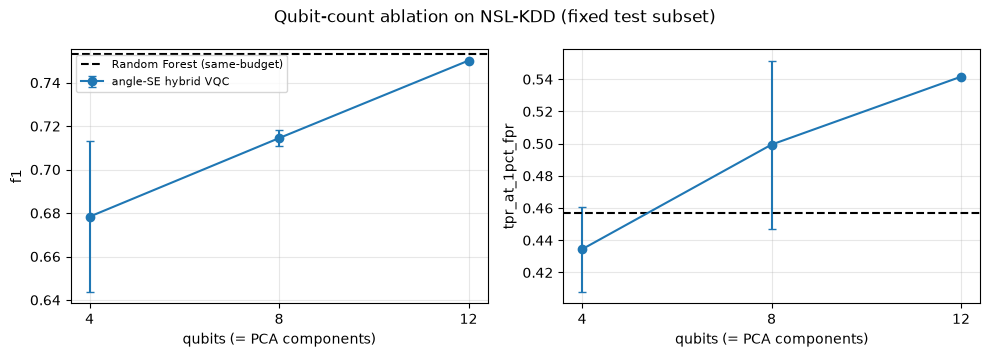

In [20]:
# ---- qubit-count ablation on the fixed test subset (paper Fig. 4): F1 and TPR@1%FPR vs width, with the best same-budget classical reference
rows = []
for q in ABL_QUBITS:
    key = f"Hyb-Angle-SE q{q}"
    ps = per_seed(key, ABL_IDX)
    for met in ("f1", "tpr_at_1pct_fpr", "tpr_at_0.1pct_fpr", "roc_auc"):
        vals = [v[0][met] for v in ps.values()]
        rows.append(dict(qubits=q, metric=met, mean=np.mean(vals), std=np.std(vals, ddof=1) if len(vals) > 1 else 0.0, n_seeds=len(vals)))
ABL = pd.DataFrame(rows)
print(ABL.pivot(index="qubits", columns="metric", values="mean").round(3).to_string())
rf_ref = {met: np.mean([v[0][met] for v in per_seed("RF [same-budget]", ABL_IDX).values()]) for met in ("f1", "tpr_at_1pct_fpr")}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, met in zip(axes, ("f1", "tpr_at_1pct_fpr")):
    d = ABL[ABL.metric == met]
    ax.errorbar(d.qubits, d["mean"], yerr=d["std"], fmt="o-", capsize=3, label="angle-SE hybrid VQC")
    ax.axhline(rf_ref[met], ls="--", color="k", label="Random Forest (same-budget)")
    ax.set_xticks(list(ABL_QUBITS)); ax.set_xlabel("qubits (= PCA components)"); ax.set_ylabel(met); ax.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.suptitle("Qubit-count ablation on NSL-KDD (fixed test subset)"); plt.tight_layout(); plt.show()


### 6.1 Regularisation sweep and the CV-to-test gap

(ii) of the audit: vary only the *classical* regularisation (Random-Forest depth, SVM `C`, MLP weight decay) and ask whether comparable regularisation closes the quantum model's gap (the Bellante et al. hypothesis).
Then the paper's methodological warning: random cross-validation inside the training split vs the official NSL-KDD test split.

In [21]:
# ---- regularisation sweep (audit component ii): vary ONLY the classical regularisation and watch the F1 / AUPRC / TPR@1%FPR
from sklearn.svm import SVC
sweep = []
s0 = Q_SEEDS[0]
sub = stratified_idx(ytr, C_TRAIN_CAP, s0)
for depth in [d["max_depth"] for d in attr.regularization_grid()["random_forest"]]:   # authors' grid: 3, 5, 8, 12, None
    rf = sklearn.ensemble.RandomForestClassifier(n_estimators=MAX_TREES, max_depth=depth, class_weight="balanced", random_state=s0, n_jobs=2).fit(Vn["Q_tr"][sub], ytr[sub])
    p = rf.predict_proba(Vn["Q_te"])[:, 1]; m = score(yte, (p >= .5).astype(int), p)
    sweep.append(dict(family="RF max_depth", setting=str(depth), f1=m["f1"], auprc=m["auprc"], tpr1=m["tpr_at_1pct_fpr"]))
sub_s = stratified_idx(ytr, min(SVM_CAP, 4000), s0)
for C in (0.1, 1.0, 10.0, 100.0):
    sv = SVC(C=C, kernel="rbf", gamma="scale", class_weight="balanced").fit(Vn["Q_tr"][sub_s], ytr[sub_s])
    d = sv.decision_function(Vn["Q_te"]); m = score(yte, (d > 0).astype(int), d)
    sweep.append(dict(family="SVM-RBF C", setting=str(C), f1=m["f1"], auprc=m["auprc"], tpr1=m["tpr_at_1pct_fpr"]))
for wd in L2_GRID:
    k = f"MatchedMLP l2={wd:g} <Hyb-Angle-SE q8>"
    sweep.append(dict(family="matched MLP weight decay", setting=f"{wd:g}", f1=RES[k]["m"][0]["f1"], auprc=RES[k]["m"][0]["auprc"], tpr1=RES[k]["m"][0]["tpr_at_1pct_fpr"]))
for qk in ("Hyb-Angle-SE q8", "QSVM-IQP (fidelity) q8"):
    m = RES[qk]["m"][0]
    sweep.append(dict(family="QUANTUM reference", setting=qk, f1=m["f1"], auprc=m["auprc"], tpr1=m["tpr_at_1pct_fpr"]))
SWEEP = pd.DataFrame(sweep).round(3)
print(SWEEP.to_string(index=False))
reg = SWEEP[SWEEP.family != "QUANTUM reference"]
best_classical_f1 = reg["f1"].max(); q_f1 = SWEEP[SWEEP.family == "QUANTUM reference"]["f1"].max()
print(f"\nbest comparably-regularised classical F1 = {best_classical_f1:.3f} vs best quantum F1 = {q_f1:.3f} -> "
      f"{'the gap is closed by classical regularisation (Bellante hypothesis supported)' if best_classical_f1 >= q_f1 - 0.01 else 'a residual quantum edge remains'}")


                  family                setting    f1  auprc  tpr1
            RF max_depth                      3 0.758  0.950 0.494
            RF max_depth                      5 0.752  0.960 0.501
            RF max_depth                      8 0.745  0.961 0.468
            RF max_depth                     12 0.755  0.965 0.471
            RF max_depth                   None 0.765  0.946 0.470
               SVM-RBF C                    0.1 0.747  0.885 0.373
               SVM-RBF C                    1.0 0.718  0.846 0.027
               SVM-RBF C                   10.0 0.716  0.847 0.071
               SVM-RBF C                  100.0 0.753  0.877 0.053
matched MLP weight decay                      0 0.761  0.942 0.492
matched MLP weight decay                  0.001 0.761  0.941 0.485
       QUANTUM reference        Hyb-Angle-SE q8 0.717  0.945 0.544
       QUANTUM reference QSVM-IQP (fidelity) q8 0.622  0.951 0.415

best comparably-regularised classical F1 = 0.765 vs best quan

In [22]:
# ---- the CV-to-test gap: why literature numbers are inflated (paper Sec. 6.1: F1 ~0.98 in training CV vs ~0.78 on KDDTest+)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
n_cv = 20000 if FAST_MODE else 40000
sub = stratified_idx(ytr, n_cv, SEED)
Xcv, ycv = Vn["F_tr"][sub], ytr[sub]
cv_f1 = []
for tr_i, va_i in StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xcv, ycv):
    rf = sklearn.ensemble.RandomForestClassifier(n_estimators=MAX_TREES, class_weight="balanced", random_state=SEED, n_jobs=2).fit(Xcv[tr_i], ycv[tr_i])
    cv_f1.append(f1_score(ycv[va_i], rf.predict(Xcv[va_i])))
rf = sklearn.ensemble.RandomForestClassifier(n_estimators=MAX_TREES, class_weight="balanced", random_state=SEED, n_jobs=2).fit(Xcv, ycv)
test_f1 = f1_score(yte, rf.predict(Vn["F_te"]))
CV_GAP = float(np.mean(cv_f1) - test_f1)
print(f"Random Forest, full view: 3-fold CV F1 inside the training split = {np.mean(cv_f1):.3f}; official KDDTest+ F1 = {test_f1:.3f}; gap = {CV_GAP:.3f}")


Random Forest, full view: 3-fold CV F1 inside the training split = 0.997; official KDDTest+ F1 = 0.747; gap = 0.250


## 7. Simulated NISQ noise

Four channels (depolarising, amplitude damping, phase damping, bit-flip/readout) on the 6-qubit hybrid, on PennyLane's density-matrix simulator `default.mixed`. In the authors' model the channel acts on every wire after the
encoding and after every ansatz layer, so deeper circuits accumulate more noise.

*Like-with-like reference.* The authors' noisy circuit applies the ansatz one layer at a time, whereas their noiseless circuit applies the whole `StronglyEntanglingLayers` template at once (the CNOT range of layers
2 and up differs). Applying weights trained on the all-at-once circuit to the layer-by-layer circuit would change the function itself, not just add noise (a first attempt made exactly that mistake: ROC-AUC fell to 0.09). So the
"noiseless" reference below is trained with the **same layer-by-layer circuit** and no channel, and the cell asserts that a vanishing channel (p = 1e-6) on the density-matrix simulator reproduces it.

  check: max |default.mixed(p=1e-6) - reference| on the model output = 9.24e-06


  seed 42 done at 151s


                     roc_auc  tpr_at_1pct_fpr    ece     f1
channel        p                                           
noiseless      0.00    0.903            0.549  0.149  0.730
depolarizing   0.01    0.902            0.549  0.200  0.730
               0.05    0.897            0.553  0.183  0.730
amplitude_damp 0.01    0.902            0.549  0.157  0.730
               0.05    0.898            0.553  0.175  0.730
phase_damp     0.01    0.902            0.549  0.151  0.731
               0.05    0.902            0.549  0.198  0.732
bit_flip       0.01    0.902            0.549  0.188  0.730
               0.05    0.897            0.553  0.231  0.718


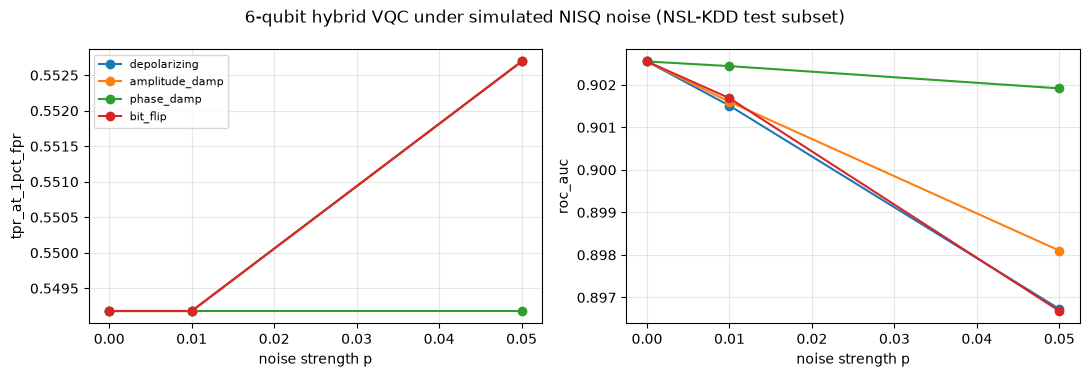

In [23]:
# ---- NISQ noise sweep on the 6-qubit angle-encoded hybrid (2 layers): depolarising / amplitude-damping / phase-damping / bit-flip
# CHOICE: the model is trained noiselessly and the noise channel (after the encoding and after every ansatz layer, as in the
# authors' quantum_model._apply_noise) is applied at inference time on the density-matrix simulator (default.mixed).
# The paper trains each noisy variant under noise; that is ~10x more expensive on a CPU, so it is not done here.
V6 = VIEWS.get(6) or make_views(Dn, n_qubits=6, seed=SEED); VIEWS[6] = V6
NOISE_IDX = stratified_idx(yte, NOISE_TEST_N, SEED)
t0 = time.time()
NOISE_ROWS = []
for s in NOISE_SEEDS:
    sub = stratified_idx(ytr, Q_TRAIN, s)
    torch.manual_seed(s)
    m6 = make_hybrid(6, 2, "angle", "strongly_entangling", noise=LAYERWISE_NOISELESS)   # same layer-by-layer circuit as the noisy ones
    train_torch(m6, V6["Q_tr"][sub], ytr[sub], Q_EPOCHS, BATCH, LR, s, class_weight=CLASS_WEIGHT)
    if s == NOISE_SEEDS[0]: MODELS["Hyb-Angle-SE q6"] = m6
    state = m6.state_dict()
    Xn, yn = V6["Q_te"][NOISE_IDX], yte[NOISE_IDX]
    # sanity check: a vanishing channel (p=1e-6) on the density-matrix simulator reproduces the noiseless reference
    chk = make_hybrid(6, 2, "angle", "strongly_entangling", noise={"type": "depolarizing", "p": 1e-6}); chk.load_state_dict(state)
    with torch.no_grad():
        dmax = float((chk(torch.tensor(Xn[:16])) - m6(torch.tensor(Xn[:16]))).abs().max())
    assert dmax < 1e-3, f"density-matrix and state-vector circuits disagree ({dmax})"
    if s == NOISE_SEEDS[0]: print(f"  check: max |default.mixed(p=1e-6) - reference| on the model output = {dmax:.2e}")
    pred, p = predict_torch(m6, Xn)
    NOISE_ROWS.append(dict(seed=s, channel="noiseless", p=0.0, **score(yn, pred, p)))
    for ch in NOISE_CHANNELS:
        for pn in NOISE_P:
            noisy = make_hybrid(6, 2, "angle", "strongly_entangling", noise={"type": ch, "p": pn})
            noisy.load_state_dict(state)
            if s == NOISE_SEEDS[0] and ch == "depolarizing" and pn == NOISE_P[-1]: MODELS["Hyb-Angle-SE q6 (noisy)"] = noisy
            pred, p = predict_torch(noisy, Xn, chunk=500)
            NOISE_ROWS.append(dict(seed=s, channel=ch, p=pn, **score(yn, pred, p)))
    print(f"  seed {s} done at {time.time()-t0:.0f}s", flush=True)
NOISE = pd.DataFrame(NOISE_ROWS)
NOISE_AGG = NOISE.groupby(["channel", "p"], sort=False)[["roc_auc", "tpr_at_1pct_fpr", "ece", "f1"]].mean().round(3)
print(NOISE_AGG.to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
base = NOISE[NOISE.channel == "noiseless"][["roc_auc", "tpr_at_1pct_fpr"]].mean()
for ax, met in zip(axes, ("tpr_at_1pct_fpr", "roc_auc")):
    for ch in NOISE_CHANNELS:
        d = NOISE[NOISE.channel == ch].groupby("p")[met].mean()
        ax.plot([0] + list(d.index), [base[met]] + list(d.values), "o-", label=ch)
    ax.set_xlabel("noise strength p"); ax.set_ylabel(met); ax.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.suptitle("6-qubit hybrid VQC under simulated NISQ noise (NSL-KDD test subset)"); plt.tight_layout(); plt.show()


## 8. The other three datasets (Table 3 analogue)

Same protocol on UNSW-NB15, CICIDS2017 and NF-ToN-IoT-v2: tuned classical models in both feature views vs the leading 8-qubit quantum model. The datasets are sub-sampled (see the choices table), so absolute numbers
differ a little from the paper's full-size runs; the *ordering* and the "near-saturated" datasets are what we check.

In [24]:
# ---- Table 3 analogue: best classical (full / same-budget) vs the leading 8-qubit quantum model, all four datasets
XRES = {}                                  # per-dataset results; keys are prefixed with the dataset name
def run_other_dataset(name):
    D, Vd = DS[name]["D"], DS[name]["V"]
    y_tr, y_te = D["ytr"], D["yte"]
    t0 = time.time(); keys = {"classical_full": [], "classical_sb": [], "quantum": []}
    for nm, lab in (("random_forest", "RF"), ("xgboost", "XGBoost"), ("svm_rbf", "SVM-RBF")):
        for view, (Xa, Xb) in {"full": (Vd["F_tr"], Vd["F_te"]), "same-budget": (Vd["Q_tr"], Vd["Q_te"])}.items():
            k = f"{name}|{lab} [{view}]"
            run_sklearn_baseline(nm, k, Xa, y_tr, Xb, y_te, X_SEEDS, cap=X_TRAIN_CAP, verbose=False)
            keys["classical_full" if view == "full" else "classical_sb"].append(k)
    for kind, lab in (("mlp", "Tuned MLP"),):
        for view, (Xa, Xb) in {"full": (Vd["F_tr"], Vd["F_te"]), "same-budget": (Vd["Q_tr"], Vd["Q_te"])}.items():
            k = f"{name}|{lab} [{view}]"
            run_torch_baseline(kind, "full" if view == "full" else "sb", k, Xa, y_tr, Xb, y_te, X_SEEDS, NN_CAP)
            keys["classical_full" if view == "full" else "classical_sb"].append(k)
    kq = f"{name}|Hyb-Angle-SE q8"
    run_hybrid(kq, Vd, y_tr, y_te, N_QUBITS, N_LAYERS, "angle", "strongly_entangling", X_SEEDS, X_Q_TRAIN, X_EPOCHS, keep=False, verbose=False)
    ks = f"{name}|QSVM-IQP (fidelity) q8"
    run_qsvm(ks, "iqp", "fidelity", Vd, y_tr, y_te, X_SEEDS, min(QSVM_N, X_TRAIN_CAP))
    keys["quantum"] = [kq, ks]
    print(f"  {name}: done in {time.time()-t0:.0f}s", flush=True)
    return keys

for name in ("UNSW-NB15", "CICIDS2017", "NF-ToN-IoT-v2"):
    XRES[name] = run_other_dataset(name)
XRES["NSL-KDD"] = dict(classical_full=[k for k in CLASSICAL_KEYS if "[full]" in k], classical_sb=SB_CLASSICAL,
                       quantum=["Hyb-Angle-SE q8", "QSVM-IQP (fidelity) q8"])
T3 = []
for name, ks in XRES.items():
    row = {"dataset": name}
    for lab, kk in (("classical full", ks["classical_full"]), ("classical same-budget", ks["classical_sb"])):
        best = max(kk, key=lambda k: mean_metric(k, "f1"))
        row[f"{lab} F1"] = round(mean_metric(best, "f1"), 3); row[f"{lab} best"] = best.split("|")[-1].split(" [")[0]
    bq = max(ks["quantum"], key=lambda k: mean_metric(k, "f1"))
    row["quantum F1"] = round(mean_metric(bq, "f1"), 3); row["quantum model"] = bq.split("|")[-1]
    for met in ("auprc", "roc_auc", "tpr_at_1pct_fpr"): row[f"Q {met}"] = round(mean_metric(bq, met), 3)
    T3.append(row)
T3 = pd.DataFrame(T3).set_index("dataset")
print(T3.to_string())


  UNSW-NB15: done in 154s


  CICIDS2017: done in 90s


  NF-ToN-IoT-v2: done in 226s


               classical full F1 classical full best  classical same-budget F1 classical same-budget best  quantum F1           quantum model  Q auprc  Q roc_auc  Q tpr_at_1pct_fpr
dataset                                                                                                                                                                             
UNSW-NB15                  0.912             XGBoost                     0.882                         RF       0.855  QSVM-IQP (fidelity) q8    0.735      0.796              0.004
CICIDS2017                 0.998             XGBoost                     0.990                         RF       0.952  QSVM-IQP (fidelity) q8    0.974      0.982              0.930
NF-ToN-IoT-v2              0.986             XGBoost                     0.973                         RF       0.938  QSVM-IQP (fidelity) q8    0.925      0.937              0.017
NSL-KDD                    0.803             SVM-RBF                     0.787                 

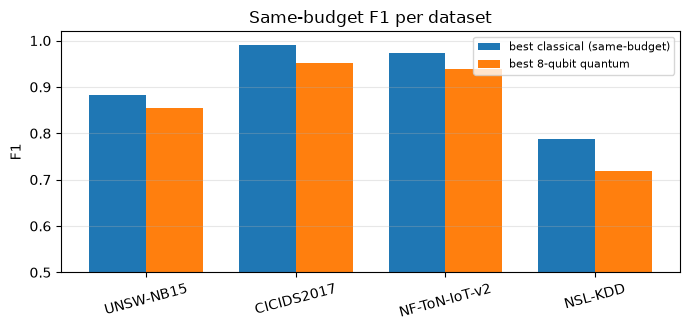

In [25]:
# ---- Fig. 3 analogue: best classical (same-budget) vs best quantum F1 per dataset
fig, ax = plt.subplots(figsize=(7, 3.4))
xs = np.arange(len(T3)); w = 0.38
ax.bar(xs - w/2, T3["classical same-budget F1"], w, label="best classical (same-budget)")
ax.bar(xs + w/2, T3["quantum F1"], w, label="best 8-qubit quantum")
ax.set_xticks(xs); ax.set_xticklabels(T3.index, rotation=15); ax.set_ylim(0.5, 1.02); ax.set_ylabel("F1"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.title("Same-budget F1 per dataset"); plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

Everything below is drawn from the **QNode that is actually executed** inside each model's `TorchLayer` (`qml.draw_mpl(model.qlayer.qnode, level="device")`, i.e. after template expansion into hardware-level gates), with qubit count, depth and
trainable-parameter count printed from `qml.specs` and the model itself.

*Assumptions where the paper omits details* (and the authors' code decides): the data are encoded with `AngleEmbedding(rotation="Y")` (angle) or the Havlicek-style IQP/ZZ map built from primitive gates (two repetitions: H, RZ(2x_i), CNOT-RZ(2(pi-x_i)(pi-x_j))-CNOT on neighbouring qubits); the ansatz is
`StronglyEntanglingLayers` (3 trainable rotations per qubit per layer plus a ring of CNOTs) or `BasicEntanglerLayers` (one RX per qubit plus a CNOT ring); every qubit's `<Z_i>` is read out and fed to a classical linear layer; the
classical pre-layer is `Linear(in, q) -> Tanh`. The circuit has no mid-circuit measurements. Noisy variants insert one noise channel per wire after the encoding and after each ansatz layer. The kernel circuits have **no trainable parameters**.

Hyb-Angle-SE q4: 4 qubits | depth 14 | 28 gates | trainable parameters: 36 quantum + 30 classical (pre-layer, read-out) = 66 total | simulator: default.qubit


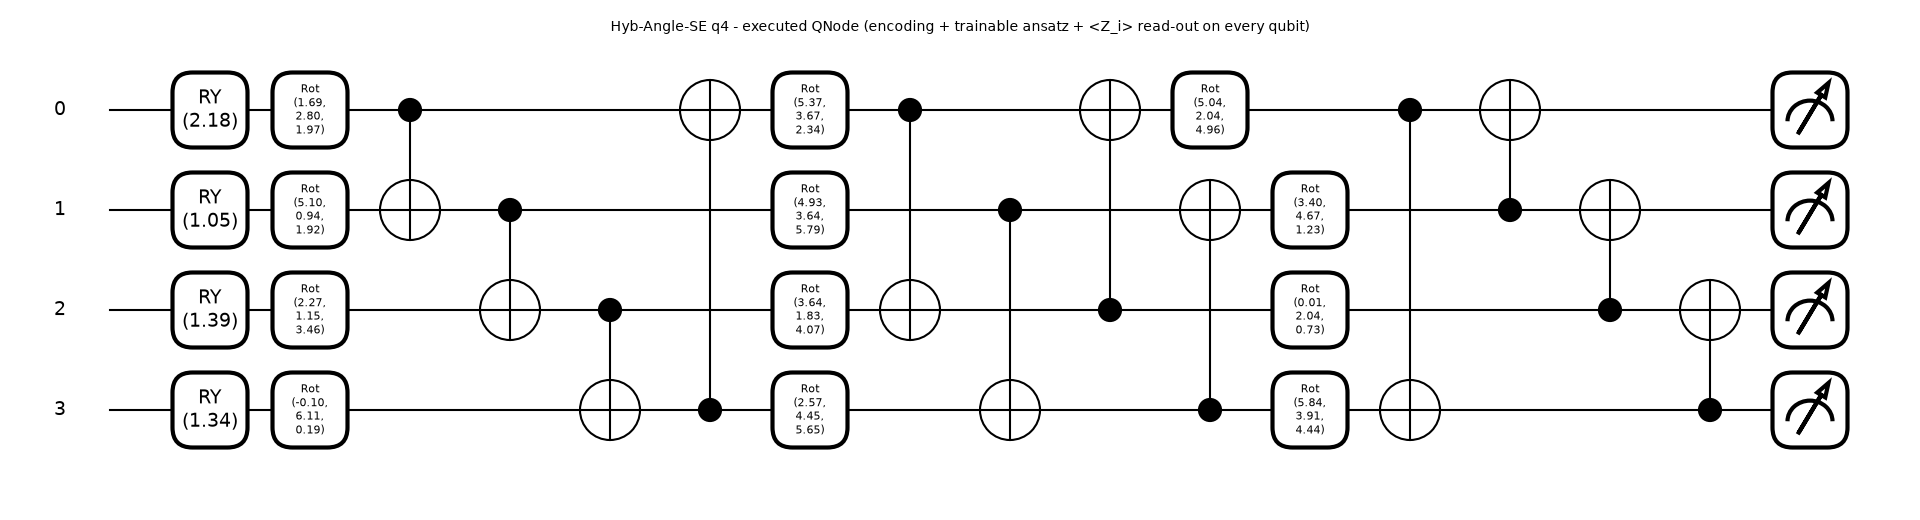

Hyb-Angle-SE q8: 8 qubits | depth 19 | 56 gates | trainable parameters: 72 quantum + 90 classical (pre-layer, read-out) = 162 total | simulator: default.qubit


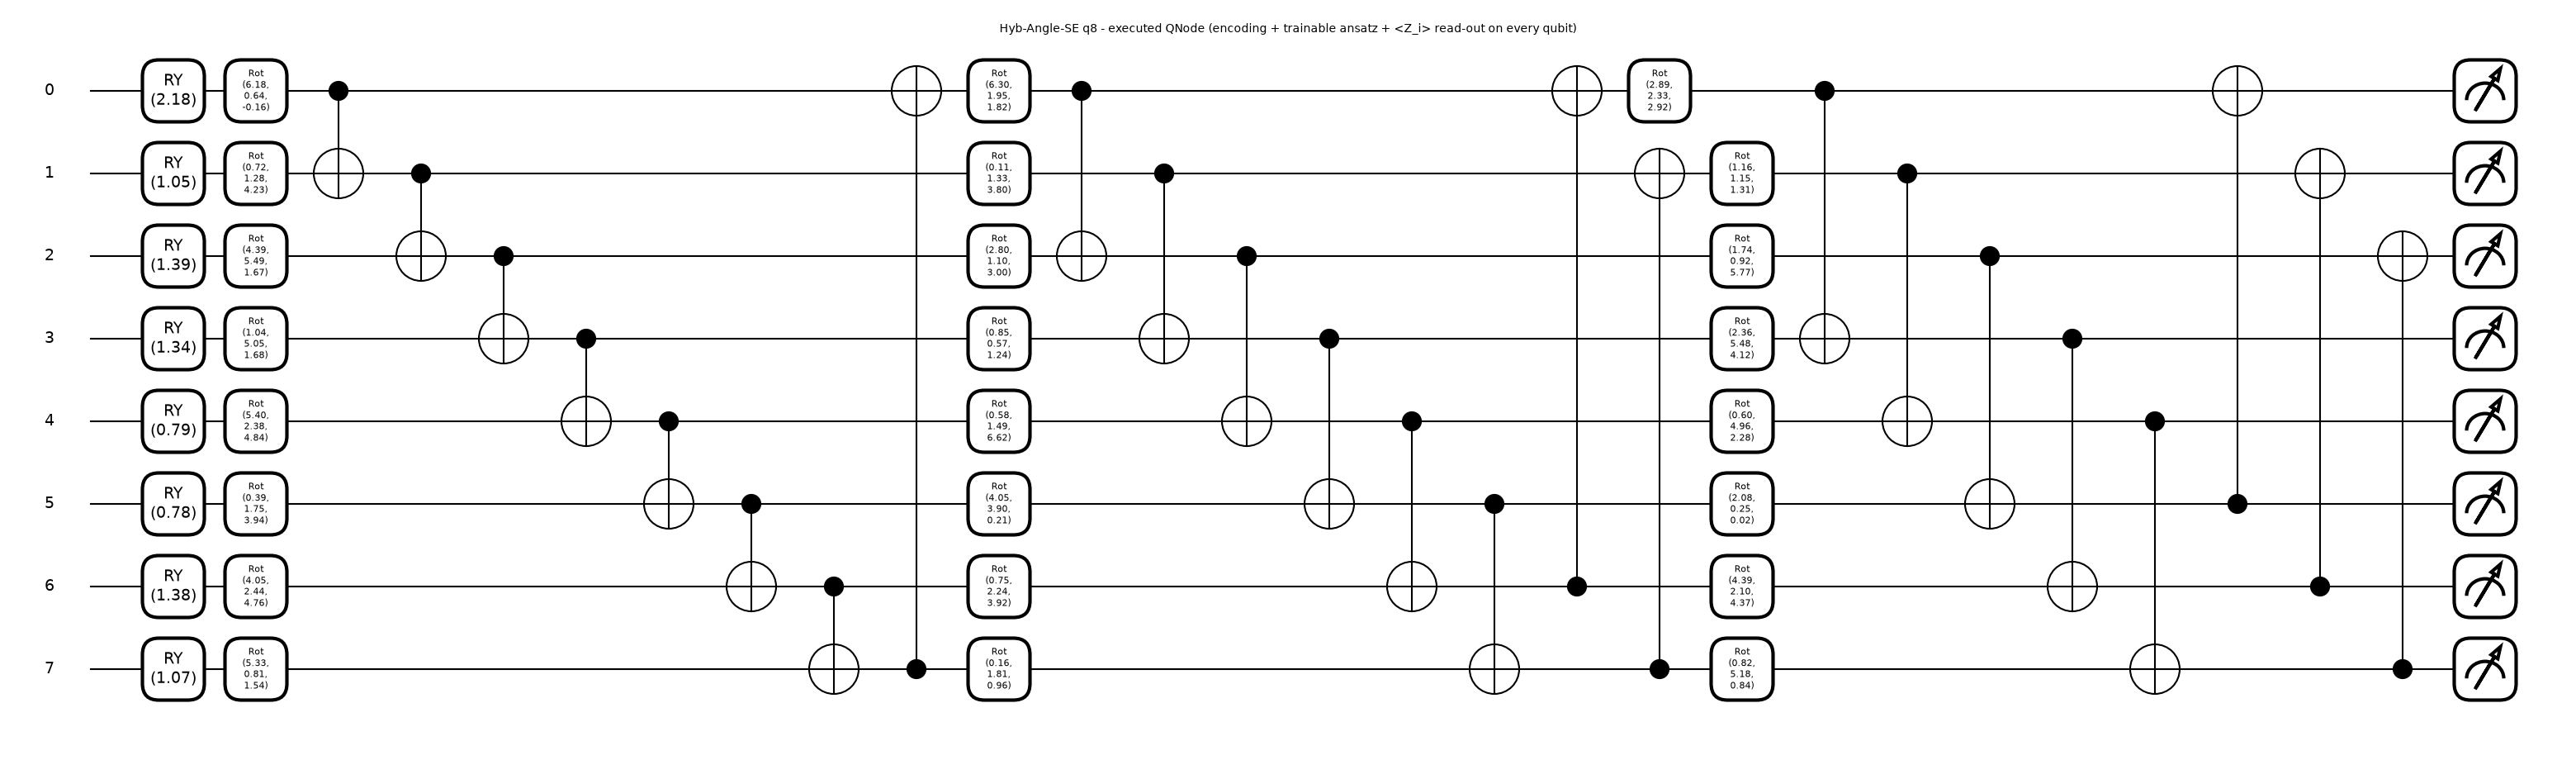

Hyb-IQP-SE q8: 8 qubits | depth 44 | 122 gates | trainable parameters: 72 quantum + 90 classical (pre-layer, read-out) = 162 total | simulator: default.qubit


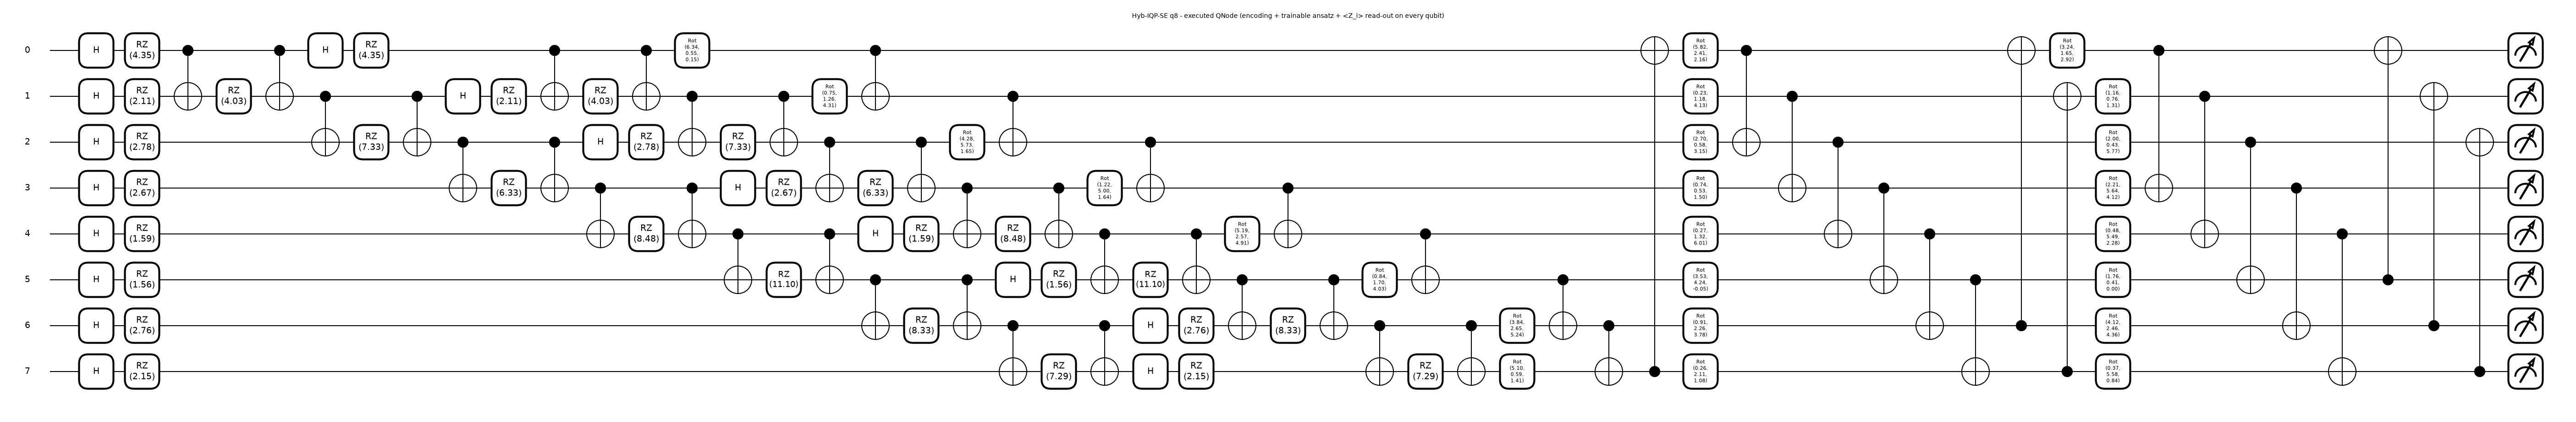

In [26]:
# ---- draw the circuits that are actually executed (PennyLane qml.draw_mpl of the real QNode inside each TorchLayer)
def circuit_info(model, name):
    ql = model.qlayer
    x0 = torch.tensor(VIEWS[model.n_qubits]["Q_tr"][0], dtype=torch.float32)   # a real training row of that qubit width
    w = ql.qnode_weights["weights"]
    try:
        spec = qml.specs(ql.qnode, level="device")(x0, w)
        res = spec["resources"] if isinstance(spec, dict) else spec.resources
        depth = res.depth; n_gates = res.num_gates
    except Exception as e:
        depth, n_gates = "n/a", "n/a"
    n_q = int(w.numel())
    print(f"{name}: {model.n_qubits} qubits | depth {depth} | {n_gates} gates | trainable parameters: {n_q} quantum + "
          f"{count_params(model) - n_q} classical (pre-layer, read-out) = {count_params(model)} total | simulator: {model.backend}")
    return x0, w

def draw(model, name):
    x0, w = circuit_info(model, name)
    try:
        fig, ax = qml.draw_mpl(model.qlayer.qnode, level="device", decimals=2)(x0, w)
    except TypeError:
        fig, ax = qml.draw_mpl(model.qlayer.qnode, decimals=2)(x0, w)
    fig.suptitle(f"{name} - executed QNode (encoding + trainable ansatz + <Z_i> read-out on every qubit)", fontsize=10)
    plt.show()

for key in ("Hyb-Angle-SE q4",):
    draw(MODELS[key], key)
for key, _, _ in HYBRIDS:
    draw(MODELS[key], key)


Hyb-Angle-SE q12: 12 qubits | depth 26 | 84 gates | trainable parameters: 108 quantum + 182 classical (pre-layer, read-out) = 290 total | simulator: default.qubit


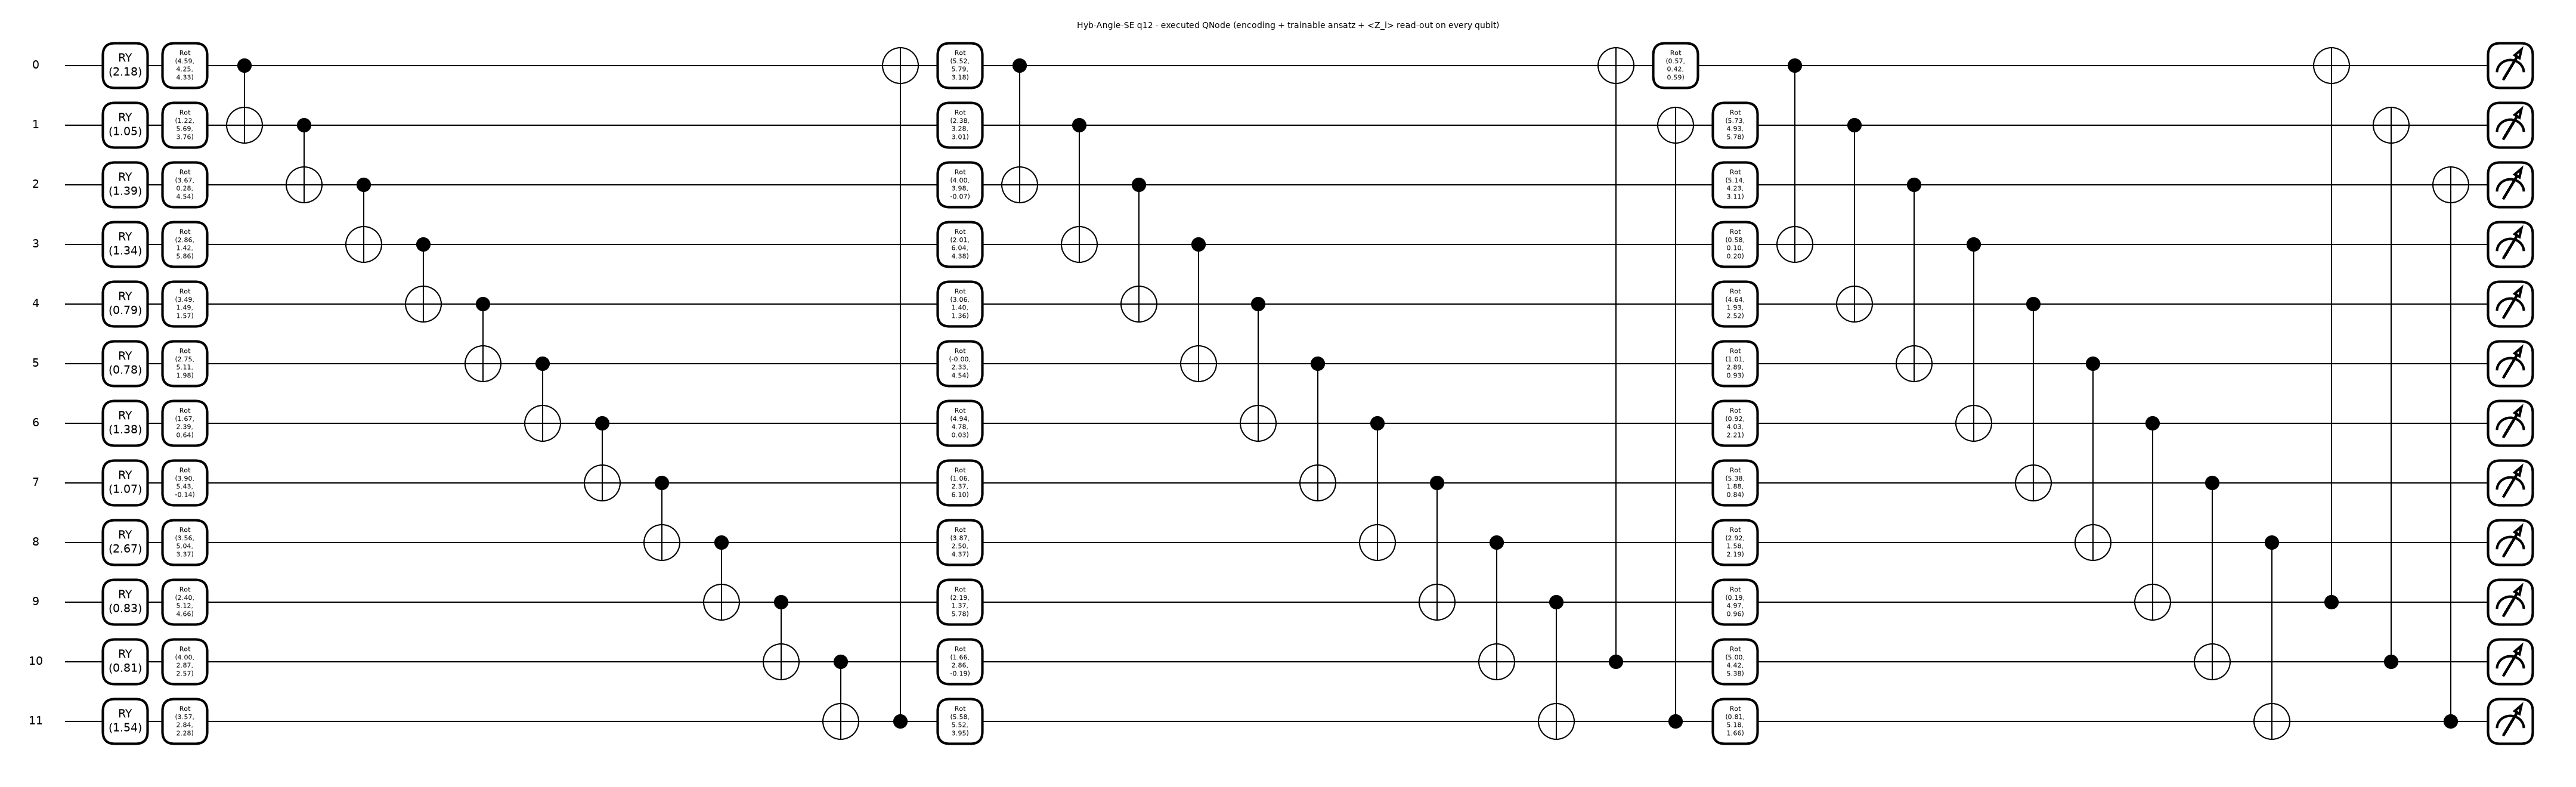

Hyb-Angle-SE q6 + depolarising noise (default.mixed density-matrix simulator): 6 qubits | depth 18 | 48 gates | trainable parameters: 36 quantum + 56 classical (pre-layer, read-out) = 92 total | simulator: default.mixed


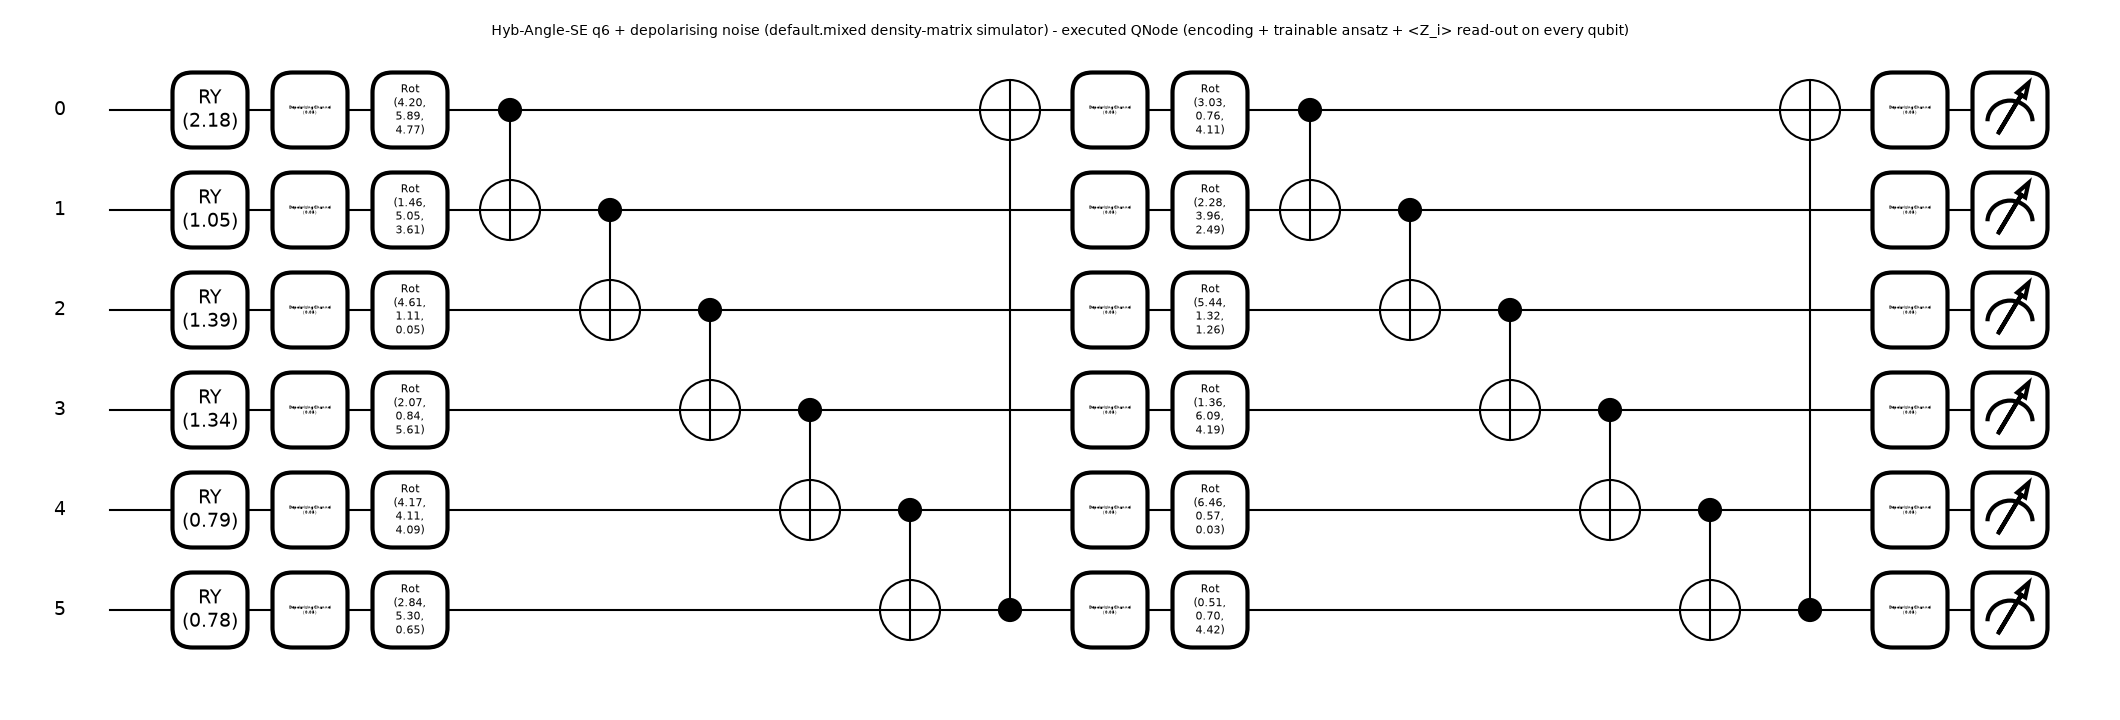

QSVM-IQP fidelity kernel: feature map U(x)|0>: 8 qubits | depth 31 | 74 gates | trainable parameters: 0 (kernel is fixed; only the SVM is trained)


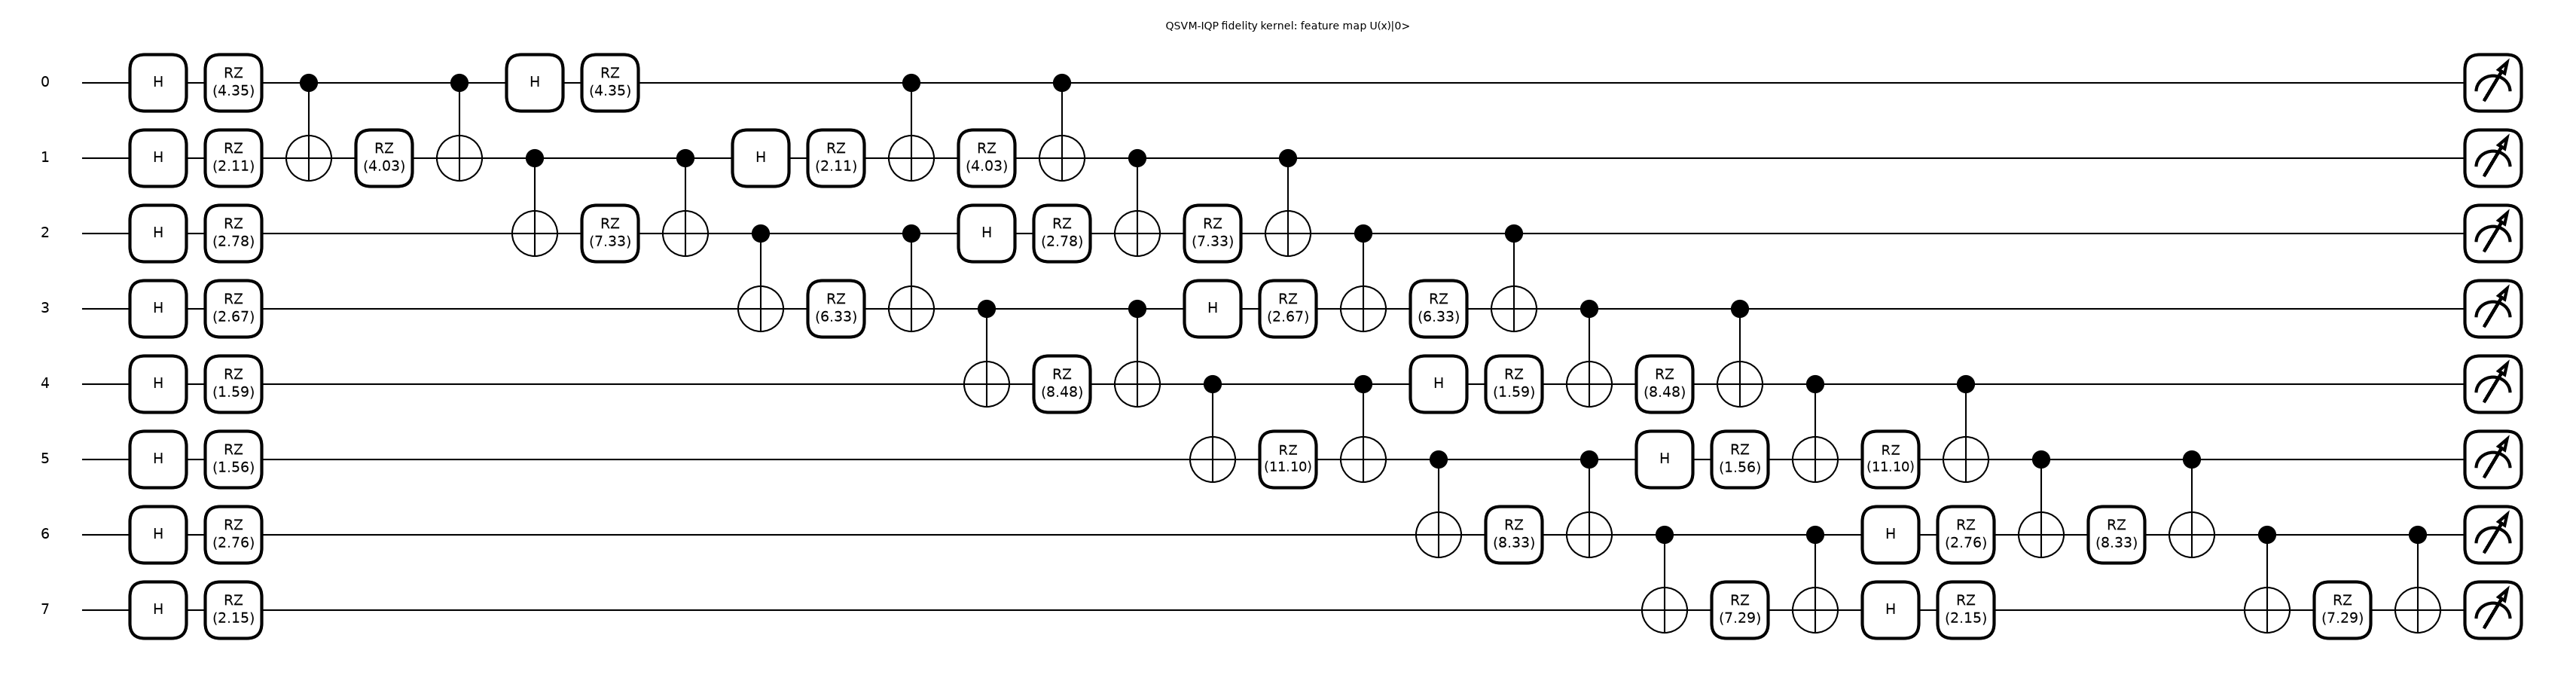

QSVM projected kernel: AngleEmbedding + <X_i>,<Y_i>,<Z_i>: 8 qubits | depth 1 | 8 gates | trainable parameters: 0 (kernel is fixed; only the SVM is trained)


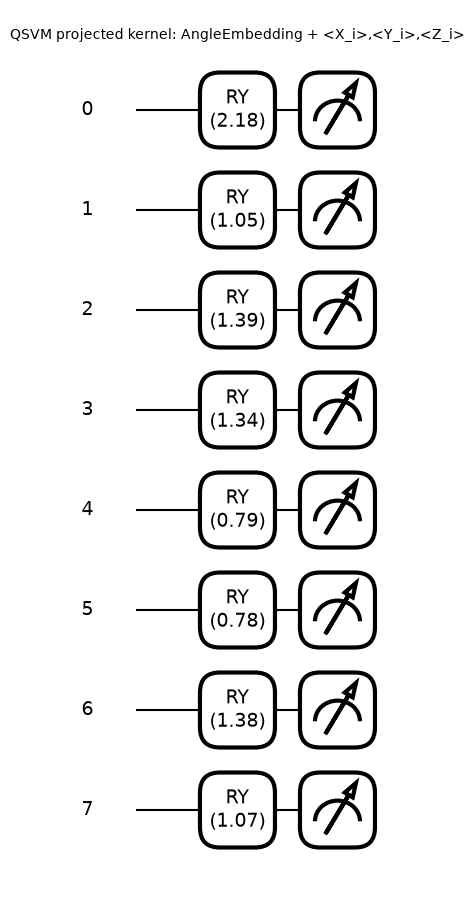

In [27]:
# 12-qubit angle hybrid (qubit-count ablation) and the NOISY 6-qubit variant (depolarising channel after the encoding and every layer)
draw(MODELS["Hyb-Angle-SE q12"], "Hyb-Angle-SE q12") if "Hyb-Angle-SE q12" in MODELS else None
draw(MODELS["Hyb-Angle-SE q6 (noisy)"], "Hyb-Angle-SE q6 + depolarising noise (default.mixed density-matrix simulator)")

# quantum-kernel circuits: the feature-map circuit of the IQP fidelity kernel (state prepared, kernel = |<phi(x)|phi(x')>|^2)
# and of the projected kernel (angle encoding + 24 Pauli expectation values)
for name, circ in (("QSVM-IQP fidelity kernel: feature map U(x)|0>", fast_k.circ), ("QSVM projected kernel: AngleEmbedding + <X_i>,<Y_i>,<Z_i>", fast_p.circ)):
    x0 = Vn["Q_tr"][0].astype(np.float64)
    spec = qml.specs(circ, level="device")(x0)
    res = spec["resources"] if isinstance(spec, dict) else spec.resources
    print(f"{name}: {N_QUBITS} qubits | depth {res.depth} | {res.num_gates} gates | trainable parameters: 0 (kernel is fixed; only the SVM is trained)")
    fig, ax = qml.draw_mpl(circ, level="device", decimals=2)(x0)
    fig.suptitle(name, fontsize=10); plt.show()


## 9. Paper versus this notebook, claim by claim

Verdict rule: a number is **reproduced** when it is within 0.02 (F1 / AUPRC / AUC / TPR / variance) of the paper's value; otherwise **not reached** (ours is lower) or **exceeded** (ours is higher), with the gap.
Direction-of-effect claims (who wins) get their own rows. "Cannot be checked" means the notebook has no way to test the claim (no GPU, different comparison family, ...).

In [28]:
# ---- paper vs notebook, claim by claim
def verdict(paper, mine, tol=0.02):
    if mine is None or (isinstance(mine, float) and np.isnan(mine)): return "cannot be checked"
    gap = float(mine) - float(paper)
    return "reproduced" if abs(gap) <= tol else (f"exceeded (gap {gap:+.3f})" if gap > 0 else f"not reached (gap {gap:+.3f})")
CLAIMS = []
def add(claim, paper, mine, tol=0.02, v=None):
    CLAIMS.append(dict(claim=claim, paper=paper, notebook=(round(float(mine), 3) if isinstance(mine, (int, float, np.floating)) and not pd.isna(mine) else mine),
                       verdict=v or verdict(paper, mine, tol)))
def arow(variant, metric, kind="best control"):
    r = AUDIT[(AUDIT.variant == variant) & (AUDIT.metric == metric) & (AUDIT.kind == kind)]
    return r.iloc[0] if len(r) else None

# data facts
add("NSL-KDD train rows", 125973, len(ytr), 0); add("NSL-KDD test rows", 22544, len(yte), 0)
add("NSL-KDD attack signatures only in test", 17, len(test_only), 0)
for name, p in (("NSL-KDD", 0.841), ("UNSW-NB15", 0.870), ("CICIDS2017", 0.924), ("NF-ToN-IoT-v2", 0.974)):
    add(f"PCA variance retained by 8 components, {name}", p, DS[name]["V"]["evr"])
# Table 3
PAPER_T3 = {"NSL-KDD": (0.803, 0.782, 0.730, 0.911, 0.865, 0.411), "UNSW-NB15": (0.912, 0.891, 0.836, 0.942, 0.924, 0.577),
            "CICIDS2017": (1.000, 1.000, 0.968, 0.992, 0.998, 0.975), "NF-ToN-IoT-v2": (0.996, 0.991, 0.949, 0.965, 0.969, 0.195)}
for name, (cf, cs, qf, qa, qr, qt) in PAPER_T3.items():
    r = T3.loc[name]
    add(f"Table 3 {name}: best classical F1, full view", cf, r["classical full F1"])
    add(f"Table 3 {name}: best classical F1, same-budget", cs, r["classical same-budget F1"])
    add(f"Table 3 {name}: leading 8-qubit quantum F1", qf, r["quantum F1"])
    add(f"Table 3 {name}: quantum AUPRC", qa, r["Q auprc"]); add(f"Table 3 {name}: quantum ROC-AUC", qr, r["Q roc_auc"])
    add(f"Table 3 {name}: quantum TPR@1%FPR", qt, r["Q tpr_at_1pct_fpr"])
    add(f"Direction, {name}: best classical (same-budget) F1 >= best quantum F1", "classical wins", "classical wins" if r["classical same-budget F1"] >= r["quantum F1"] else "quantum wins",
        v="reproduced" if r["classical same-budget F1"] >= r["quantum F1"] else "not reached")
add("CV-to-test F1 gap on NSL-KDD (Random Forest)", 0.20, CV_GAP, 0.05)
# attribution audit
for met, pv in (("auprc", 0.075), ("roc_auc", 0.134), ("tpr_at_1pct_fpr", 0.152)):
    r = arow("QSVM-IQP (fidelity) q8", met, "surrogate (rf-kernel)")
    if r is None: r = arow("QSVM-IQP (fidelity) q8", met)
    add(f"Audit: QSVM-IQP minus random-feature kernel, {met} (delta)", pv, None if r is None else r["delta"])
    add(f"Audit: QSVM-IQP > random-feature kernel on {met}, FDR-robust (q<0.05)", "yes (q<0.05)", "n/a" if r is None else f"{'yes' if r['delta'] > 0 else 'no'} (q={r['q_BH']:.3f})",
        v="cannot be checked" if r is None else ("reproduced" if (r["delta"] > 0 and r["q_BH"] < 0.05) else ("direction reproduced, not FDR-robust here" if r["delta"] > 0 else "not reached")))
r1, r01, rf1 = arow("Hyb-Angle-SE q4", "tpr_at_1pct_fpr"), arow("Hyb-Angle-SE q4", "tpr_at_0.1pct_fpr"), arow("Hyb-Angle-SE q4", "f1")
add("Hybrid q4: TPR@1%FPR", 0.517, None if r1 is None else r1["quantum"]); add("Best control TPR@1%FPR vs hybrid q4 (Random Forest 0.467)", 0.467, None if r1 is None else r1["control"])
add("Hybrid q4 minus best control, TPR@1%FPR (delta)", 0.050, None if r1 is None else r1["delta"])
add("Hybrid q4 beats best classical at TPR@1%FPR", "yes (p=0.005, q=0.030)", "n/a" if r1 is None else f"{'yes' if r1['delta'] > 0 else 'no'} (p={r1['p']:.3f}, q={r1['q_BH']:.3f})",
    v="cannot be checked" if r1 is None else ("reproduced" if (r1["delta"] > 0 and r1["q_BH"] < 0.05) else ("direction reproduced, not FDR-robust here" if r1["delta"] > 0 else "not reached")))
add("Hybrid q4: TPR@0.1%FPR", 0.407, None if r01 is None else r01["quantum"]); add("Hybrid q4: F1", 0.759, None if rf1 is None else rf1["quantum"])
r12f, r12t = arow("Hyb-Angle-SE q12", "f1"), arow("Hyb-Angle-SE q12", "tpr_at_1pct_fpr")
add("Hybrid q12: F1", 0.724, None if r12f is None else r12f["quantum"]); add("Hybrid q12 minus best control, F1 (delta)", -0.039, None if r12f is None else r12f["delta"])
add("Hybrid q12: TPR@1%FPR", 0.346, None if r12t is None else r12t["quantum"]); add("Hybrid q12 minus best control, TPR@1%FPR (delta)", -0.121, None if r12t is None else r12t["delta"])
q4_t = ABL[(ABL.qubits == 4) & (ABL.metric == "tpr_at_1pct_fpr")]["mean"].iloc[0]; q12_t = ABL[(ABL.qubits == 12) & (ABL.metric == "tpr_at_1pct_fpr")]["mean"].iloc[0]
add("TPR@1%FPR of the hybrid declines from 4 to 12 qubits", "yes", "yes" if q12_t < q4_t else "no", v="reproduced" if q12_t < q4_t else "not reached")
# aggregate: matched classical controls close the gap (hybrid vs matched MLP, F1)
rm = arow("Hyb-Angle-SE q8", "f1")
add("Aggregate quantum advantage disappears against matched classical controls (q8 hybrid F1 - best control)", "<= 0", None if rm is None else rm["delta"],
    v="cannot be checked" if rm is None else ("reproduced" if rm["delta"] <= 0.005 else "not reached"))
# noise
nb = NOISE[NOISE.channel == "noiseless"][["roc_auc", "tpr_at_1pct_fpr", "ece"]].mean()
add("Noise baseline (6 qubits): ROC-AUC", 0.846, nb["roc_auc"]); add("Noise baseline (6 qubits): TPR@1%FPR", 0.422, nb["tpr_at_1pct_fpr"]); add("Noise baseline (6 qubits): ECE", 0.191, nb["ece"])
mild = NOISE[NOISE.channel.isin(["depolarizing", "amplitude_damp", "phase_damp"])].groupby(["channel", "p"])["tpr_at_1pct_fpr"].mean()
add("Mild noise (depol/ampdamp/phase) leaves TPR@1%FPR unchanged: max |change|", 0.01, float((mild - nb["tpr_at_1pct_fpr"]).abs().max()), 0.03,
    v="reproduced" if float((mild - nb["tpr_at_1pct_fpr"]).abs().max()) <= 0.03 else "not reached")
bf = NOISE[(NOISE.channel == "bit_flip") & (NOISE.p == max(NOISE_P))]["tpr_at_1pct_fpr"].mean()
add("Bit-flip (readout) noise lowers TPR@1%FPR", "yes (0.379 at p=0.05)", f"{bf:.3f} at p={max(NOISE_P)}",
    v="reproduced" if bf < nb["tpr_at_1pct_fpr"] - 0.005 else "not reached")
add("GPU slower than CPU at QML-IDS qubit counts (Table 5)", "8-14x", "no GPU here", v="cannot be checked")
add("108-comparison BH family: 13 quantum-favouring / 27 classical-favouring survivors", "13 / 27", f"{fav_q} / {len(sig)-fav_q} of {len(AUDIT)}", v="cannot be checked (different family)")
CMP = pd.DataFrame(CLAIMS)
pd.set_option("display.width", 220, "display.max_colwidth", 90)
print(CMP.to_string(index=False))
print("\nverdict counts:\n", CMP.verdict.str.split(" ").str[0].value_counts().to_string())


                                                                                                  claim                  paper              notebook                              verdict
                                                                                     NSL-KDD train rows                 125973              125973.0                           reproduced
                                                                                      NSL-KDD test rows                  22544               22544.0                           reproduced
                                                                 NSL-KDD attack signatures only in test                     17                  17.0                           reproduced
                                                         PCA variance retained by 8 components, NSL-KDD                  0.841                 0.841                           reproduced
                                                       PCA variance re

### What this run shows (FAST_MODE = True: 2 seeds, 600 training rows, 6 epochs; numbers are from the executed cells above)

**Reproduced.** (1) Tuned classical models match or beat the quantum models on aggregate F1 on all four datasets (same-budget best classical vs best 8-qubit quantum F1: NSL-KDD 0.787 vs 0.719, UNSW-NB15 0.882 vs 0.855,
CICIDS2017 0.990 vs 0.952, NF-ToN-IoT-v2 0.973 vs 0.938); the NSL-KDD Table-3 F1 values (0.803 / 0.787 / 0.719) agree with the paper's (0.803 / 0.782 / 0.730) within 0.02. (2) The CV-to-test collapse on NSL-KDD is real and even larger here
(Random Forest F1 0.997 in training CV vs 0.747 on `KDDTest+`, gap 0.25 vs about 0.20 in the paper). (3) Matched classical controls close the aggregate gap of the 8-qubit hybrid (F1 -0.068 vs the best control). (4) The IQP quantum-kernel SVM beats
its random-feature surrogate on AUPRC, ROC-AUC and TPR@1 %FPR with q < 0.05 (AUPRC +0.123, ROC-AUC +0.231, TPR@1 %FPR +0.166); the direction and significance agree with the paper, the margins are larger because our surrogate (512 random features, gamma = 1, 500 rows) is untuned.
(5) Mild simulated noise (depolarising, amplitude damping, phase damping) leaves TPR@1 %FPR unchanged (max change 0.004).

**Not reproduced.** (a) The 4-qubit hybrid does **not** beat the best classical model at TPR@1 %FPR here (0.452 vs Random Forest 0.473 on the same 4 PCA components, and 0.552 for the parameter-matched MLP): the paper's second "FDR-robust quantum advantage" is not seen.
(b) The decline of TPR@1 %FPR from 4 to 12 qubits is not seen (the 12-qubit model, one seed and a smaller budget, gets 0.54 on the test subset against 0.43 for 4 qubits). (c) Bit-flip readout noise does not lower TPR@1 %FPR here (it only raises ECE and slightly lowers F1).
(d) On UNSW-NB15 and NF-ToN-IoT-v2 the leading quantum model (an IQP kernel on 500 training rows) has near-zero TPR@1 %FPR (0.004 and 0.017) against 0.58 and 0.20 in the paper; our sub-sampled data and tiny quantum budgets are the likely cause. (e) PCA variance retained by 8 components is lower on our CICIDS2017 / NF-ToN slices (0.887 / 0.934 vs 0.924 / 0.974).

**Cannot be checked.** GPU-vs-CPU backend timing (no GPU) and the exact 108-comparison BH family.

*Caveats.* Two seeds and a bootstrap with 300 resamples (p-values print as 0.000 = below 1/301); the "FDR-robust" counts are dominated by the large fixed test set, not by training-run variability. The full-budget run (2,000 rows x 20 epochs x 3 seeds) was not executed
because it would take well over 90 minutes on the shared CPU used here.

## 10. Reading the paper critically

- **The paper's strongest message is methodological and it holds up.** The large gap between cross-validated and official-test F1, and the fact that matched classical controls and cheap regularisation sweeps reach the quantum models' numbers, are
  easy to re-check and are the reason a "quantum accuracy" headline should not be trusted without a same-budget classical baseline.
- **Small-sample statistics.** Three quantum seeds cannot support a seed-level Wilcoxon test (the two-sided floor is p = 0.25); the operating-point claims rest on a paired bootstrap over *one* fixed test set, which measures test-set sampling noise, not training-run variability.
  A 4-qubit "win" at TPR@1 %FPR is therefore a statement about one trained model on one split.
- **Multiple comparisons.** The Benjamini-Hochberg family (108 comparisons in the paper, a few dozen here) is defined by the authors; a different family changes which results survive, and the paper itself concedes that the 4-qubit result does not survive the stricter Holm correction.
- **Where an advantage could come from.** The projected-quantum-kernel and the 4-qubit hybrid both have *low capacity*; a plausible reading is implicit regularisation rather than a quantum feature space, which is exactly the Bellante hypothesis the paper otherwise confirms.
  Only a real-hardware or larger-scale study could separate those explanations.
- **Simulation caveats.** All results are noiseless or Markovian-noise simulations; the inference-time noise used here is optimistic compared with training under noise, and neither captures crosstalk or connectivity.
- **Substitutions here.** Sub-sampled UNSW/CICIDS/ToN data, short training budgets, a smaller classical search and a different simulator back-end (proved equivalent) mean absolute numbers can differ from the paper; conclusions are drawn from orderings and from effects larger than the seed spread.
- **Licence.** The released code is non-commercial and attribution-restricted (ORAL v1.0); anyone building on it should read the licence first.

## 11. Exercises

1. **Amplitude encoding.** Add `("Hyb-Amp-SE q8", "amplitude", "strongly_entangling")` to `HYBRIDS`. The authors report it as unstable; does it train here, and what does the audit say?
2. **Bandwidth of the surrogate.** The random-feature kernel uses `gamma = 1.0`. Sweep `gamma` over `{0.1, 0.3, 1, 3}` using a validation split of the training data only and re-run the QSVM-vs-surrogate comparison. Does the quantum kernel's advantage survive a properly tuned surrogate?
3. **Train under noise.** Replace the inference-time noise in section 7 by training each noisy model (use fewer rows and epochs). Is the "mild noise improves ROC-AUC" effect still there?
4. **Seeds and the Wilcoxon floor.** Increase `Q_SEEDS` to five seeds and compute the paired Wilcoxon p-value of the 4-qubit hybrid vs Random Forest at TPR@1 %FPR with `evaluation.paired_t_test`. What is the smallest p-value five seeds can give?
5. **Distribution shift.** Re-split NSL-KDD with a random 70/30 split of `KDDTrain+` only and re-run the 4-qubit vs Random-Forest comparison. Does the low-FPR "quantum edge" survive when there is no novel-attack shift?